# Laboratório 10: Sarsa com aproximação de função (FrozenLake e CliffWalking)

## Importações

In [ ]:
!pip install gymnasium[toy-text]                                                # CliffWalking e FrozenLake (inclui o pygame)
!pip install tqdm pandas scikit-learn                                           # Progresso, tabelas e a rede neural
!pip install gdown                                                              # Download do rl_utils_lab10.py e das figuras

In [ ]:
import os                                                                       # Verificação de arquivos
import gdown                                                                    # Download de arquivos do Google Drive
import gymnasium as gym                                                         # Ambientes de aprendizado por reforço
from gymnasium.wrappers import RecordEpisodeStatistics                          # Estatísticas por episódio
import numpy as np                                                              # Operações numéricas e vetoriais
import pandas as pd                                                             # Tabelas de resultados
import matplotlib.pyplot as plt                                                 # Gráficos
from tqdm.auto import tqdm                                                      # Barra de progresso
from typing import NamedTuple, Optional, List, Tuple                            # Anotações de tipo e tuplas nomeadas
from collections import deque                                                   # Fila com tamanho máximo
from sklearn.neural_network import MLPRegressor                                 # Rede neural que aproxima q(s,.,w)

## Funções auxiliares para visualização

In [ ]:
RL_UTILS_URL = "https://drive.google.com/file/d/1ZZayKYDz8EXwXWQ5NS6PYpq1Xh2-yyVM/view?usp=sharing"

if not os.path.exists("rl_utils_lab10.py"):                                     # Baixa o módulo só se ainda não existir
    try:
        gdown.download(RL_UTILS_URL, "rl_utils_lab10.py", quiet=True, fuzzy=True)
    except Exception as error:
        print(f"Falha no download: {error}")

from rl_utils_lab10 import (                                                    # Funções auxiliares do Laboratório 10
    plot_results, plot_comparison,                                              # Curvas de treinamento
    simulate_trajectory, plot_trajectory,                                       # Trajetória sobre a grade
    show_one_episode,                                                           # Animação de um episódio
    plot_tabular, plot_policy_distributions,                                    # Mapas de calor de q, pi e v; barras pi(.|s)
    plot_update_effect, print_network,                                          # Efeito de uma atualização; resumo da rede
    show_figure,                                                                # Figuras do laboratório
)

## Ambiente: nova instância

O laboratório usa o `FrozenLake-v1`, do [Gymnasium](https://gymnasium.farama.org/environments/toy_text/frozen_lake/), na grade $4 \times 4$.

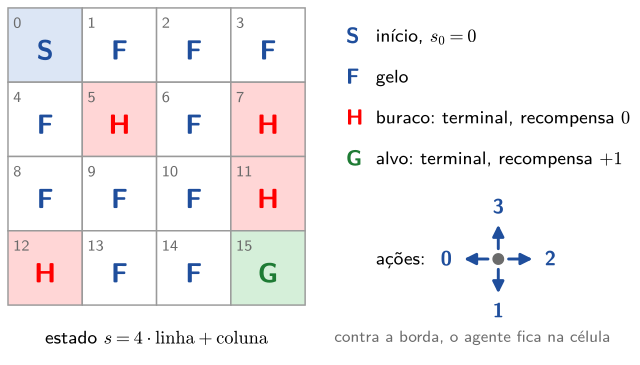

In [ ]:
show_figure("mapa_frozenlake")                                                  # Mapa do FrozenLake 4x4

- **Estado:** o índice da célula, `4 * linha + coluna`, que é também a observação devolvida pelo ambiente.
- **Ações:** 0 (esquerda), 1 (baixo), 2 (direita) e 3 (cima). Contra a borda, o agente fica na mesma célula.
- **Recompensa:** $+1$ ao chegar ao alvo e $0$ em qualquer outro passo, inclusive ao cair num buraco.
- **Fim do episódio:** os buracos e o alvo são estados terminais. O episódio também termina ao atingir um limite de passos.
- **Escorregamento:** desligado (`is_slippery=False`): o agente sempre se move na direção escolhida.
- **Modelo:** não é usado. O agente aprende só com as amostras de experiência devolvidas por `env.step`, e não com o `env.P` do Laboratório 3.

A célula abaixo define as constantes e `make_env`, que cria o ambiente com o limite de passos e o envolve com o wrapper `RecordEpisodeStatistics`. Cada treinamento deve usar um ambiente novo, criado por `make_env`.

<details>
<summary><b>Detalhes:</b> <code>RecordEpisodeStatistics</code> </summary>

- No último passo de cada episódio, acrescenta a `info` a entrada `info["episode"]`, com:
  - `"r"`: a recompensa total, isto é, a soma das recompensas, sem desconto;
  - `"l"`: a duração, em passos;
  - `"t"`: o tempo de execução, em segundos.
- Guarda esses valores dos últimos `STATS_BUFFER_LENGTH` episódios nas filas `return_queue`, `length_queue` e `time_queue`, usadas nas médias da barra de progresso.
- Um ambiente novo começa com as filas vazias.

</details>

In [ ]:
ENV_ID = "FrozenLake-v1"                                                        # Identificador do ambiente
MAX_EPISODE_STEPS = 100                                                         # Limite de passos por episódio
GOAL_STATE = 15                                                                 # Estado-alvo
STATS_BUFFER_LENGTH = 100                                                       # Tamanho das filas e janela das médias
SEED = 42                                                                       # Semente para reprodutibilidade


def make_env(render_mode: Optional[str] = "rgb_array") -> gym.Env:
    env = gym.make(ENV_ID, render_mode=render_mode,                             # "rgb_array": render() devolve imagem
                   max_episode_steps=MAX_EPISODE_STEPS,                         # truncated = True no limite
                   map_name="4x4", is_slippery=False)                           # Grade 4x4, sem escorregamento
    return RecordEpisodeStatistics(env, buffer_length=STATS_BUFFER_LENGTH)      # Registra r, l e t dos episódios


env = make_env()                                                                # Instância para inspeção

`env.reset` inicia um episódio e devolve o estado inicial $s_0$ e o dicionário `info`.

In [ ]:
obs, info = env.reset(seed=SEED)                                                # Estado inicial s_0
obs, info

(0, {'prob': 1})

`env.render()` devolve a imagem do estado atual, um array com shape `(altura, largura, 3)`.

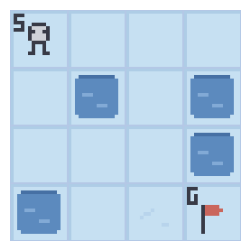

(256, 256, 3)

In [ ]:
img = env.render()                                                              # Imagem RGB do estado atual
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.axis("off")
plt.show()
img.shape                                                                       # (altura, largura, canais)

`env.step` executa um passo. Ele recebe só a ação $a_t$, porque o ambiente já guarda o estado atual $s_t$:

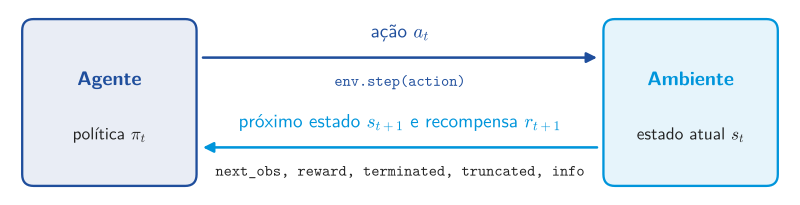

In [ ]:
show_figure("env_step")                                                         # Interação agente-ambiente em env.step

| Saída | Nomenclatura | Significado |
|---|---|---|
| `next_obs` | $s_{t+1}$ | próximo estado |
| `reward` | $r_{t+1}$ | recompensa do passo |
| `terminated` | $s_{t+1}$ terminal | `True` ao chegar a um estado terminal: o episódio acaba, e $v(s_{t+1})= q(s_{t+1}, \cdot)=0$ |
| `truncated` | — | `True` ao atingir o limite de passos: o episódio para, mas $s_{t+1}$ **não** é terminal |
| `info` | — | dados auxiliares (`"prob"` e, no último passo, `"episode"`) |

> **Atenção:** $a_{t+1}$ não vem do ambiente: o agente a sorteia em $s_{t+1}$, com a sua política.

A célula abaixo executa duas ações a partir de $s_0 = 0$:
- `1` (baixo), que leva a $s_1 = 4$;
- `2` (direita), que leva ao buraco $s_2 = 5$.

Observe `reward` e `terminated` no segundo passo.

In [ ]:
env.step(1)                                                                     # a_0 = 1 (baixo): s_0 = 0 -> s_1 = 4
next_obs, reward, terminated, truncated, info = env.step(2)                     # a_1 = 2 (direita): buraco 5
next_obs, reward, terminated, truncated, info

(5,
 0,
 True,
 False,
 {'prob': 1.0, 'episode': {'r': 0.0, 'l': 2, 't': 0.116763}})

A célula abaixo executa um episódio com ações sorteadas uniformemente por `env.action_space.sample()`. Agindo ao acaso, o agente costuma cair num buraco antes de chegar ao alvo; no último passo, `info["episode"]` traz as estatísticas do wrapper.

In [ ]:
env.action_space.seed(SEED)                                                     # Fixa o sorteio das ações aleatórias
obs, info = env.reset(seed=SEED)
episode_over = False
while not episode_over:                                                         # Um episódio com ações aleatórias
    action = env.action_space.sample()                                          # Ação sorteada uniformemente
    obs, reward, terminated, truncated, info = env.step(action)
    episode_over = terminated or truncated                                      # Estado terminal ou limite de passos
obs, terminated, truncated, info["episode"]

(5, True, False, {'r': 0.0, 'l': 4, 't': 0.000462})

## Algoritmo: Sarsa com aproximação de função

Nos métodos tabulares, as estimativas $q(s,a)$ ficam numa tabela, com uma entrada independente por par $(s,a)$. Com aproximação de função, a estimativa é a saída de uma função com parâmetros $w$, aqui uma rede neural: $\hat q(s,a,w)$. Os parâmetros são compartilhados por todos os pares, e corrigir $w$ para um par pode mudar as estimativas dos outros:

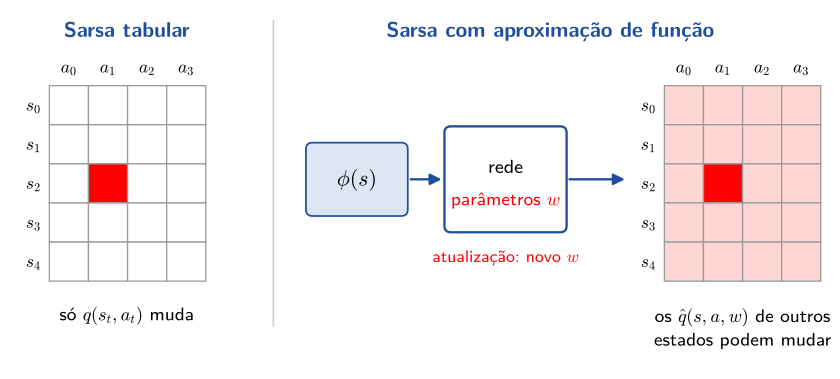

In [ ]:
show_figure("tabela_vs_rede")                                                   # Uma atualização: tabela e rede

### Vetor de características

A entrada da rede é o vetor de características $\phi(s)$, que descreve o estado. O laboratório usa duas escolhas:

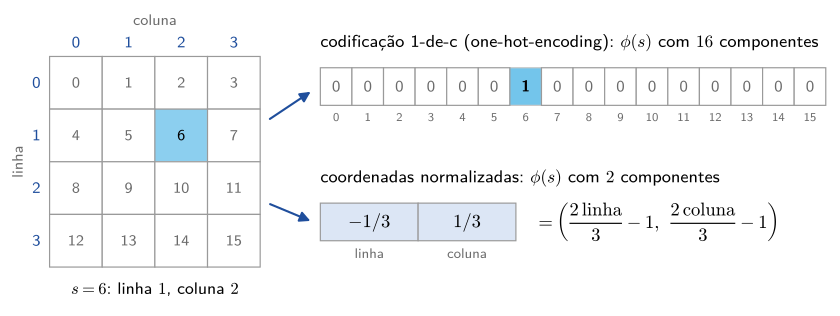

In [ ]:
show_figure("vetor_caracteristicas")                                            # phi(s) one-hot e por coordenadas

- **codificação 1-de-c (one-hot encoding):** uma componente por estado, igual a $1$ na posição $s$ e a $0$ nas demais. Os vetores de estados diferentes não têm componentes não nulas em comum.
- **coordenadas normalizadas:** componentes $(\text{linha}, \text{coluna})$, cada uma em $[-1, 1]$, para qualquer tamanho de grade: a linha e a coluna de $s$, levadas para esse intervalo. Estados vizinhos têm vetores próximos:

$$\phi(s) = \left(\frac{2\,\text{linha}}{n_{\text{linhas}} - 1} - 1,\ \frac{2\,\text{coluna}}{n_{\text{colunas}} - 1} - 1\right)$$

As funções abaixo devolvem a matriz `Phi`, de shape `(n_estados, d)`, cuja linha `s` é $\phi(s)$, com $d$ componentes. O exemplo treina um agente com cada vetor de características.

In [ ]:
def one_hot_features(n_states: int) -> np.ndarray:
    # np.eye cria uma matriz identidade (n_states x n_states)
    # A linha s contém o vetor one-hot do estado s: exatamente um 1 na posição s e 0 em todas as outras
    return np.eye(n_states)


def coordinate_features(n_rows: int, n_cols: int) -> np.ndarray:
    # np.divmod converte o índice linear do estado s (0 a n_states-1) em coordenadas bidimensionais (linha, coluna)
    rows, cols = np.divmod(np.arange(n_rows * n_cols), n_cols)
    # Normaliza as coordenadas linearmente para o intervalo [-1, 1]:
    # 2 * rows / (n_rows - 1) - 1 mapeia a linha 0 para -1 e a última linha para +1
    # 2 * cols / (n_cols - 1) - 1 mapeia a coluna 0 para -1 e a última coluna para +1
    return np.column_stack([2 * rows / (n_rows - 1) - 1,
                            2 * cols / (n_cols - 1) - 1])

Phi_one_hot = one_hot_features(16)                                              # phi(s) one-hot: matriz (16, 16)
Phi_coords = coordinate_features(4, 4)                                          # phi(s) por coordenadas: matriz (16, 2)
print(Phi_coords)
print(Phi_one_hot)


[[-1.         -1.        ]
 [-1.         -0.33333333]
 [-1.          0.33333333]
 [-1.          1.        ]
 [-0.33333333 -1.        ]
 [-0.33333333 -0.33333333]
 [-0.33333333  0.33333333]
 [-0.33333333  1.        ]
 [ 0.33333333 -1.        ]
 [ 0.33333333 -0.33333333]
 [ 0.33333333  0.33333333]
 [ 0.33333333  1.        ]
 [ 1.         -1.        ]
 [ 1.         -0.33333333]
 [ 1.          0.33333333]
 [ 1.          1.        ]]
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0

### Rede neural

A rede neural recebe $\phi(s)$ e prediz, numa só passagem, as estimativas de todas as ações em $s$: o vetor $\hat q(s,\cdot,w)$, com uma componente por ação. Os parâmetros $w$ são todos os pesos e vieses.

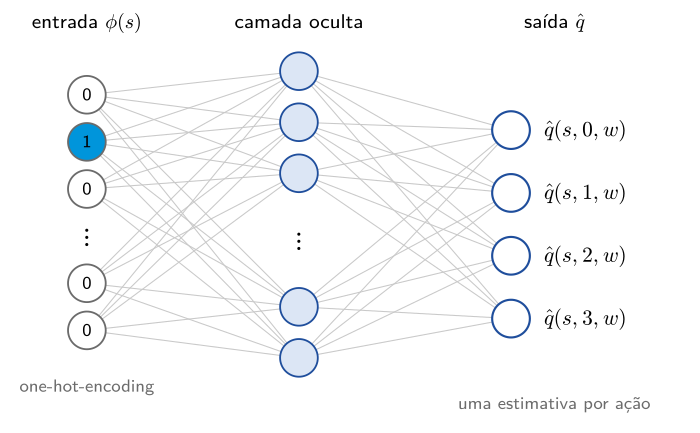

In [ ]:
show_figure("rede_q")                                                           # A rede do exemplo: phi(s) -> q(s,.,w)

O agente usa o [`MLPRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html) do scikit-learn. No exemplo, a rede tem uma camada oculta de 4 neurônios com ativação $\tanh$, e a saída é linear; a entrada tem 16 componentes com o one-hot e 2 componentes com as coordenadas normalizadas. Os argumentos usados:

| Argumento | Descrição |
|---|---|
| `hidden_layer_sizes` | neurônios de cada camada oculta, como `(4,)` ou `(64, 64)` |
| `activation` | ativação das camadas ocultas: `"tanh"`, `"relu"`, `"logistic"` ou `"identity"` |
| `solver` | otimizador: `"adam"` ou `"sgd"` |
| `learning_rate_init` | taxa de aprendizado: $\alpha$ |
| `alpha` | peso da regularização L2 (zero aqui) |
| `random_state` | semente dos pesos iniciais |

Diferentemente da tabela dos laboratórios anteriores, inicializada com zeros, $\hat q(s,a,w)$ começa **aleatória**: é a saída da rede com os pesos iniciais sorteados.

<details>
<summary><b>Detalhes:</b> criação dos pesos</summary>

O `MLPRegressor` só cria os pesos na primeira chamada de `partial_fit`, que também já dá um passo do otimizador. O agente faz essa chamada no construtor, com alvo zero em todos os estados: um único passo, pequeno, que mantém as estimativas essencialmente aleatórias.

</details>

### Atualização

Como no Sarsa tabular, a amostra de experiência $(s_t, a_t, r_{t+1}, s_{t+1}, a_{t+1})$ é utilizada para construir o alvo TD. A diferença é que se atualizam os parâmetros $w$ em vez de uma entrada da tabela:

$$
\underbrace{w_{t+1}}_{\substack{\text{novos}\\ \text{parâmetros}}}
\;=\;
\underbrace{w_t}_{\substack{\text{parâmetros}\\ \text{atuais}}}
\;-\;
\underbrace{\alpha}_{\substack{\text{taxa de}\\ \text{aprendizado}}}
\,
\underbrace{\Big[\, \hat q(s_t,a_t,w_t) \;-\; {\color{red}{\overbrace{r_{t+1} + \gamma\, \hat q(s_{t+1},a_{t+1},w_t)}^{\text{alvo TD: } \bar q_t}}} \,\Big]}_{\text{erro TD: } \delta_t}
\,
\underbrace{\nabla_w \hat q(s_t,a_t,w_t)}_{\substack{\text{gradiente da}\\ \text{estimativa}}}
$$

- O gradiente $\nabla_w \hat q(s_t,a_t,w_t)$ diz quanto cada parâmetro afeta a estimativa do par visitado. O passo muda os parâmetros, e com eles podem mudar as estimativas $\hat q(s,a,w)$ dos outros pares.
- O alvo $\bar q_t$ também depende de $w$, mas é tratado como constante: o gradiente é só o da estimativa.
- Se $s_{t+1}$ é terminal, o alvo é só $\bar q_t = r_{t+1}$.


**Com o `partial_fit`.** O `MLPRegressor` reduz o erro quadrático entre a sua saída e um alvo $y$, um vetor com uma componente por ação. Para obter a atualização acima, o agente monta $y$ a partir das próprias estimativas, trocando só a componente da ação executada:

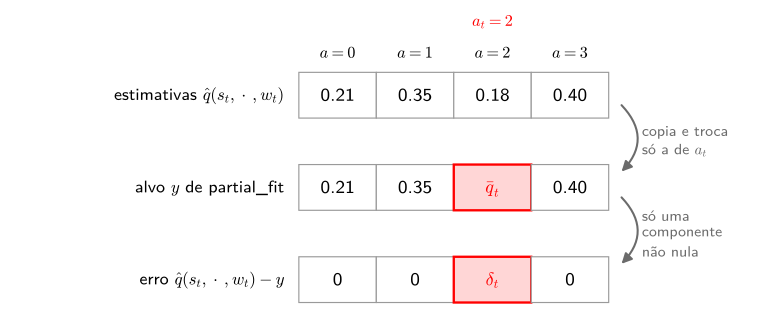

In [ ]:
show_figure("alvo_vetorial")                                                    # Vetor-alvo de partial_fit

O erro da saída é nulo em todas as ações, exceto em $a_t$, em que vale $\delta_t$. O gradiente da função objetivo (erro quadrático) é então $\delta_t\, \nabla_w \hat q(s_t,a_t,w_t)$, e uma chamada de `partial_fit` com $\phi(s_t)$ e $y$ dá **um** passo do otimizador.

### Política $\epsilon$-gulosa

A política é $\epsilon$-gulosa em relação às estimativas atuais:

$$
\pi(a \mid s) =
\begin{cases}
1 - \dfrac{\epsilon}{|\mathcal{A}(s)|}\big(|\mathcal{A}(s)| - 1\big), & \text{se } a = \arg\max\limits_{a} \hat q(s,a,w) \\[10pt]
\dfrac{\epsilon}{|\mathcal{A}(s)|}, & \text{caso contrário}
\end{cases}
$$

Com $\epsilon = 0.1$ e quatro ações:

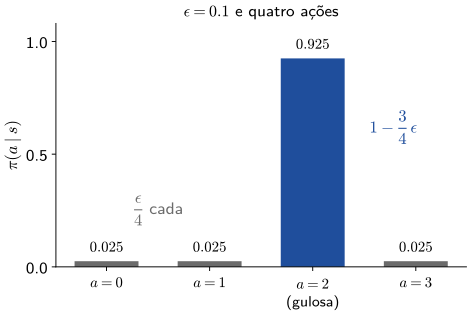

In [ ]:
show_figure("epsilon_gulosa")                                                   # Política epsilon-gulosa com epsilon = 0.1

Durante o treinamento, o agente não guarda uma tabela $\pi$: calcula $\pi(\cdot \mid s)$ a partir de $\hat q(s,\cdot,w)$ **só no estado em que vai agir**. Como cada atualização muda $w$, a política pode mudar em qualquer estado, e não só em $s_t$; as matrizes de $\hat q$ e $\pi$ de todos os estados só são construídas ao fim do treinamento, para a avaliação e as visualizações.

> **On-policy** ($\pi_b = \pi_T$): $a_{t+1}$ é sorteada pela mesma política que o agente executa, e é ela que será executada no passo seguinte.

**Implementação.** O código do exemplo está pronto:

| Parte | Descrição |
|---|---|
| `Params` | reúne os hiperparâmetros e a arquitetura da rede |
| `SarsaNNAgent` | guarda a rede e as características; sorteia as ações; atualiza $w$ |
| `run_episode_and_train` | executa um episódio, atualizando o agente a cada passo |
| `train_agent` | repete os episódios e registra as métricas |

### Hiperparâmetros

`Params` reúne os hiperparâmetros e a arquitetura da rede; `n_states` e `n_actions` vêm do ambiente.

| Campo | Hiperparâmetro |
|---|---|
| `n_episodes` | número de episódios, $N$ |
| `hidden_layer_sizes` | neurônios de cada camada oculta |
| `activation` | ativação das camadas ocultas |
| `solver` | otimizador |
| `learning_rate` | taxa de aprendizado, $\alpha$ |
| `discount_factor` | fator de desconto, $\gamma$ |
| `epsilon` | parâmetro $\epsilon$ da política |

<details>
<summary><b>Detalhes:</b> como variar um hiperparâmetro com <code>_replace</code></summary>

Uma `NamedTuple` não pode ser alterada depois de criada, mas `params._replace(learning_rate=0.0005)` devolve uma cópia de `params` com $\alpha$ trocado. Isso facilita mudar uma coisa de cada vez.

</details>

In [ ]:
class Params(NamedTuple):
    n_states: int                                                               # Número de estados |S|
    n_actions: int                                                              # Número de ações |A|
    n_episodes: int                                                             # Número de episódios (N)
    hidden_layer_sizes: Tuple[int, ...]                                         # Neurônios de cada camada oculta
    activation: str                                                             # Ativação das camadas ocultas
    solver: str                                                                 # Otimizador: "adam" ou "sgd"
    learning_rate: float                                                        # Taxa de aprendizado (alpha)
    discount_factor: float                                                      # Fator de desconto (gamma)
    epsilon: float                                                              # Parâmetro da política epsilon-gulosa

### Agente

`SarsaNNAgent` está pronto. O agente guarda:

| Atributo | Conteúdo |
|---|---|
| `self.net` | a rede (`MLPRegressor`), com os parâmetros $w$ |
| `self.Phi` | as características; a linha `self.Phi[s]` é $\phi(s)$ |
| `self.learning_rate`, `self.discount_factor`, `self.epsilon` | $\alpha$, $\gamma$, $\epsilon$ |
| `self.rng` | gerador de números aleatórios do agente |
| `self.visit_counts` | número de visitas a cada par $(s,a)$ |
| `self.Q` | matriz de $\hat q(s,a,w)$ de todos os estados, construída por `build_tables` |
| `self.Pi` | matriz de $\pi(a \mid s)$ de todos os estados, construída por `build_tables` |

Os métodos e o que devolvem:

| Método | Devolve |
|---|---|
| `get_q_values(obs)` | o vetor $\hat q(s,\cdot,w)$ |
| `get_action_probs(obs)` | o vetor $\pi(\cdot \mid s)$, calculado só no estado `obs` |
| `get_greedy_action(obs)` | a ação gulosa; em caso de empate, a de menor índice |
| `sample_action(obs)` | `(action, is_exploratory)`: a ação sorteada e `1` se ela não é a gulosa |
| `policy(obs, deterministic)` | a ação gulosa ou uma ação sorteada; usado nas visualizações |
| `get_target_value(...)` | o alvo $\bar q_t$ |
| `update_Q(...)` | o erro TD $\delta_t$, depois de montar $y$ e chamar `partial_fit` |
| `update(...)` | o erro TD $\delta_t$; chama `update_Q` e registra a visita ao par $(s_t, a_t)$ |
| `build_tables()` | nada; calcula `self.Q` e `self.Pi` com o $w$ atual |

Os nomes seguem os dos laboratórios anteriores, com uma diferença: não há `update_policy`. Como a política não fica guardada numa tabela, não há linha a atualizar depois de cada passo: `get_action_probs` calcula $\pi(\cdot \mid s)$ quando o agente vai agir em $s$, e `build_tables` constrói as matrizes completas uma vez, ao fim do treinamento.

Nos métodos, os argumentos correspondem a:

| `obs` | `action` | `reward` | `next_obs` | `next_action` | `terminated` |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $s_t$ | $a_t$ | $r_{t+1}$ | $s_{t+1}$ | $a_{t+1}$ | $s_{t+1}$ é terminal? |

> **Atenção:** só `terminated` zera o futuro. No truncamento, $s_{t+1}$ não é terminal e $\gamma\, \hat q(s_{t+1},a_{t+1},w_t)$ continua no alvo; por isso os métodos não recebem `truncated`.

In [ ]:
class SarsaNNAgent:
    def __init__(self, params: Params, Phi: np.ndarray, seed: int = SEED):
        # Número total de estados do ambiente (ex: 16 no FrozenLake ou 48 no CliffWalking)
        self.n_states = params.n_states
        # Número de ações possíveis (4 ações: Cima, Direita, Baixo, Esquerda)
        self.n_actions = params.n_actions
        # Taxa de aprendizado alpha da rede neural
        self.learning_rate = params.learning_rate
        # Fator de desconto temporal gamma
        self.discount_factor = params.discount_factor
        # Epsilon para exploração comportamental epsilon-gulosa
        self.epsilon = params.epsilon
        # Matriz de características Phi: cada linha s contém o vetor de entrada phi(s) do estado s
        self.Phi = np.asarray(Phi, dtype=float)
        assert self.Phi.shape[0] == self.n_states, "Phi precisa de uma linha por estado"
        # Gerador pseudoaleatório do agente para garantir reprodutibilidade
        self.rng = np.random.default_rng(seed)
        # Aproximador de função: Perceptron Multicamadas (MLP) do scikit-learn
        self.net = MLPRegressor(
            hidden_layer_sizes=params.hidden_layer_sizes,                       # Tupla definindo neurônios nas camadas ocultas
            activation=params.activation,                                       # Função de ativação (ex: 'relu' ou 'identity')
            solver=params.solver,                                               # Otimizador (ex: 'sgd' ou 'adam')
            learning_rate_init=self.learning_rate,                              # alpha inicial
            alpha=0.0,                                                          # Regularização L2 desativada (peso 0)
            momentum=0.0,                                                       # Momento zerado para atualização estocástica pura
            shuffle=False,                                                      # Mantém a ordem das amostras
            random_state=seed,                                                  # Semente para inicialização dos pesos w_0
        )
        # Inicializa a estrutura da rede neural com uma primeira chamada a partial_fit com zeros
        zeros = np.zeros((self.n_states, self.n_actions))
        self.net.partial_fit(self.Phi, zeros)
        # Contador de visitas a cada par (s, a)
        self.visit_counts = np.zeros((self.n_states, self.n_actions))
        self.Q = None                                                           # Tabela Q construída em build_tables
        self.Pi = None                                                          # Tabela Pi construída em build_tables


    def get_q_values(self, obs: int) -> np.ndarray:
        # Passa o vetor de características phi(obs) pela rede neural e obtém as estimativas q(obs, a, w) para as 4 ações
        return self.net.predict(self.Phi[obs:obs + 1])[0]


    def get_action_probs(self, obs: int) -> np.ndarray:
        # Obtém as estimativas q da rede para o estado obs
        q = self.get_q_values(obs)
        # Distribui a probabilidade base de exploração (epsilon / |A|)
        probs = np.full(self.n_actions, self.epsilon / self.n_actions)
        # Adiciona (1 - epsilon) à ação de maior estimativa gulosa argmax_a q
        probs[int(np.argmax(q))] += 1.0 - self.epsilon
        return probs


    def get_greedy_action(self, obs: int) -> int:
        # Retorna o índice da ação com maior valor estimado q(obs, a, w); empate escolhe o menor índice
        return int(np.argmax(self.get_q_values(obs)))


    def sample_action(self, obs: int) -> Tuple[int, int]:
        # Sorteia ação de acordo com a distribuição epsilon-gulosa calculada pela rede
        probs = self.get_action_probs(obs)
        action = int(self.rng.choice(self.n_actions, p=probs))
        # Flag de exploração: 1 se a ação sorteada não for a gulosa
        is_exploratory = int(action != int(np.argmax(probs)))
        return action, is_exploratory


    def policy(self, obs: int, deterministic: bool = False) -> int:
        # Se deterministic=True (modo deploy): escolhe estritamente a ação gulosa
        if deterministic:
            return self.get_greedy_action(obs)
        # Se deterministic=False (modo treino): sorteia com exploração epsilon-gulosa
        return self.sample_action(obs)[0]


    def get_target_value(self, next_obs: int, next_action: int, reward: float,
                         terminated: bool) -> float:
        # Se o próximo estado for terminal: não há estimativa futura, alvo = r_{t+1}
        if terminated:
            return float(reward)
        # Caso contrário: calcula q(s_{t+1}, a_{t+1}, w_t) usando a rede neural
        q_next = self.get_q_values(next_obs)[next_action]
        # Alvo TD do SARSA com aproximação de função: r_{t+1} + gamma * q(s_{t+1}, a_{t+1}, w_t)
        return float(reward + self.discount_factor * q_next)


    def update_Q(self, obs: int, action: int, next_obs: int, next_action: int,
                 reward: float, terminated: bool) -> float:
        # x é o vetor de características phi(s_t) com formato (1, dimensões)
        x = self.Phi[obs:obs + 1]
        # y é o vetor com as estimativas atuais q(s_t, ., w_t) para todas as ações
        y = self.net.predict(x)
        # Calcula o alvo TD escalar
        target_value = self.get_target_value(next_obs, next_action, reward, terminated)
        # Erro TD: delta_t = estimativa atual - alvo
        td_error = float(y[0, action] - target_value)
        # NOVO ALVO DA REDE: mantemos as predições das outras ações e alteramos APENAS a ação executada a_t
        y[0, action] = target_value
        # partial_fit realiza um passo de descida do gradiente (SGD) atualizando os pesos da rede w_t -> w_{t+1}
        self.net.partial_fit(x, y)
        return td_error


    def update(self, obs: int, action: int, next_obs: int, next_action: int,
               reward: float, terminated: bool) -> float:
        # 1. Atualiza os pesos da rede neural
        td_error = self.update_Q(obs, action, next_obs, next_action,
                                 reward, terminated)
        # 2. Incrementa contador de visitas
        self.visit_counts[obs, action] += 1
        return td_error


    def build_tables(self) -> None:
        # Passa todas as características Phi pela rede de uma só vez para gerar a tabela Q completa (n_states x n_actions)
        self.Q = self.net.predict(self.Phi)
        greedy = np.argmax(self.Q, axis=1)
        self.Pi = np.full(self.Q.shape, self.epsilon / self.n_actions)
        self.Pi[np.arange(self.n_states), greedy] += 1.0 - self.epsilon


### Episódio de treinamento

`run_episode_and_train` está pronta. O início sorteia $a_0$ em $s_0$; cada iteração do laço segue os passos da figura:

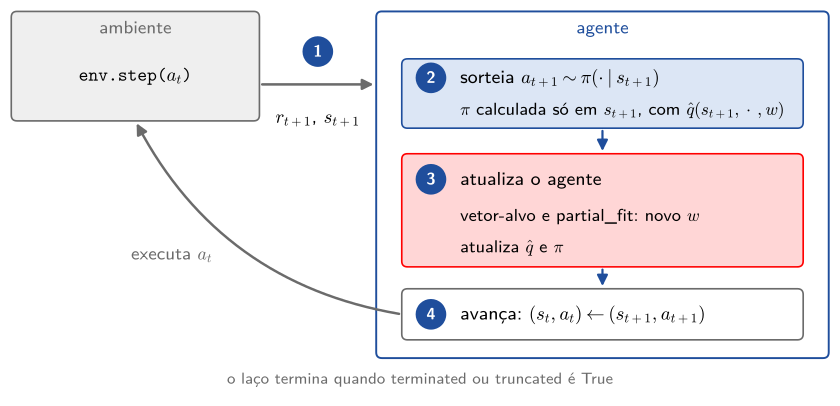

In [ ]:
show_figure("sarsa_fa_passo")                                                   # Um passo do Sarsa com aproximação de função

1. executa $a_t$ com `env.step`, que devolve $r_{t+1}$ e $s_{t+1}$;
2. sorteia $a_{t+1}$ em $s_{t+1}$, com $\pi(\cdot \mid s_{t+1})$ calculada só nesse estado, a partir de $\hat q(s_{t+1},\cdot,w)$;
3. atualiza o agente com $(s_t, a_t, r_{t+1}, s_{t+1}, a_{t+1})$: um passo de `partial_fit` muda $w$, o que atualiza $\hat q$ e $\pi$;
4. avança: $(s_t, a_t) \leftarrow (s_{t+1}, a_{t+1})$.

O laço termina quando `terminated` ou `truncated` é `True`. A função devolve:

- `info["episode"]`: recompensa total, duração e tempo do episódio;
- `n_exploratory_actions`: número de ações não gulosas executadas;
- a média de $|\delta_t|$ nos passos do episódio;
- `terminated` e o último estado, que dizem se o episódio terminou no alvo.

In [ ]:
def run_episode_and_train(agent: SarsaNNAgent, env: gym.Env, seed: int = SEED):
    # Reseta o ambiente para o estado inicial s_0
    obs, _info = env.reset(seed=seed)
    # Sorteia a primeira ação a_0 segundo a rede neural
    action, is_exploratory = agent.sample_action(obs)

    episode_over = False
    n_exploratory_actions = 0
    abs_td_errors = []
    terminated = False
    info = {}

    while not episode_over:
        # 1. Executa a_t no ambiente
        next_obs, reward, terminated, truncated, info = env.step(action)
        # 2. Sorteia a_{t+1} no próximo estado antes da atualização (característica On-Policy do SARSA)
        next_action, next_is_exploratory = agent.sample_action(next_obs)
        # 3. Dá um passo de gradiente ajustando os pesos da rede w_t -> w_{t+1}
        td_error = agent.update(obs, action, next_obs, next_action,
                                reward, terminated)
        # Registra o módulo do erro TD para monitoramento da convergência
        abs_td_errors.append(abs(td_error))
        n_exploratory_actions += is_exploratory
        # 4. Transição de tempo
        obs, action = next_obs, next_action
        is_exploratory = next_is_exploratory
        episode_over = terminated or truncated

    mean_abs_td = float(np.mean(abs_td_errors))
    return info["episode"], n_exploratory_actions, mean_abs_td, terminated, obs


### Laço externo

`train_agent` está pronta. Ela repete `run_episode_and_train` por `n_episodes` episódios, cada um com uma semente sorteada pelo gerador do agente, e devolve as séries numa `TrainingHistory`:

| Campo | Série, por episódio |
|---|---|
| `returns` | recompensa total |
| `lengths` | duração, em passos |
| `times` | tempo de execução, em segundos |
| `exploration_rates` | proporção de ações não gulosas executadas |
| `successes` | 1 se o episódio terminou no alvo (`GOAL_STATE`), 0 caso contrário |
| `td_errors` | média de $|\delta_t|$ nos passos do episódio |

A barra de progresso mostra as médias dos últimos `STATS_BUFFER_LENGTH` episódios, calculadas com as filas do `RecordEpisodeStatistics`. Ao final, `train_agent` chama `agent.build_tables()`, que calcula $\hat q$ e $\pi$ em todos os estados com o $w$ final e os guarda em `agent.Q` e `agent.Pi`, usados na avaliação e nas visualizações.

<details>
<summary><b>Detalhes:</b> a tupla nomeada <code>TrainingHistory</code></summary>

Cada campo pode ser acessado pelo nome, como em `history.returns`, e a tupla também pode ser desempacotada na ordem em que os campos foram definidos.

</details>

In [ ]:
class TrainingHistory(NamedTuple):
    returns: List[float]                                                        # Recompensa total (sem desconto) por episódio
    lengths: List[int]                                                          # Duração (passos) por episódio
    times: List[float]                                                          # Tempo de execução (s) por episódio
    exploration_rates: List[float]                                              # Proporção de ações exploratórias
    successes: List[int]                                                        # 1 se terminou no alvo, 0 caso contrário
    td_errors: List[float]                                                      # Média de |delta_t| por episódio


def train_agent(agent: SarsaNNAgent, env: gym.Env, n_episodes: int) -> TrainingHistory:
    returns, lengths, times, exploration_rates = [], [], [], []                 # Históricos por episódio
    successes, td_errors = [], []
    success_queue = deque(maxlen=env.return_queue.maxlen)                       # Janela recente de sucessos
    pbar = tqdm(range(n_episodes), desc="Treinando", unit="episódio")           # Barra de progresso

    for episode in pbar:
        seed = int(agent.rng.integers(2**32))                                   # Semente do episódio
        episode_data, n_exploratory_actions, mean_abs_td, terminated, last_obs = (
            run_episode_and_train(agent=agent, env=env, seed=seed))             # Treina em um episódio

        episode_length = int(episode_data["l"])                                 # Número de passos
        exploration_rate = n_exploratory_actions / episode_length               # Proporção de ações exploratórias
        success = int(terminated and last_obs == GOAL_STATE)                    # 1 se terminou no alvo

        returns.append(float(episode_data["r"]))                                # Recompensa total
        lengths.append(episode_length)                                          # Duração
        times.append(float(episode_data["t"]))                                  # Tempo
        exploration_rates.append(exploration_rate)                              # Exploração
        successes.append(success)                                               # Sucesso
        td_errors.append(mean_abs_td)                                           # Erro TD médio
        success_queue.append(success)                                           # Fila de sucessos recentes

        pbar.set_postfix({                                                      # Médias recentes na barra
            "recompensa_media": f"{np.mean(env.return_queue):.1f}",
            "passos_medio": f"{np.mean(env.length_queue):.1f}",
            "erro_td": f"{mean_abs_td:.3f}",
            "sucesso": f"{np.mean(success_queue):.3f}",
        })

    agent.build_tables()                                                        # q e pi de todos os estados, com o w final
    return TrainingHistory(returns, lengths, times, exploration_rates, successes, td_errors)

## Experimento

### Configuração do exemplo

O exemplo treina dois agentes no FrozenLake, um com cada vetor de características, com a mesma rede e os mesmos hiperparâmetros:

In [ ]:
params = Params(
    n_states=env.observation_space.n,                                           # 16 estados
    n_actions=env.action_space.n,                                               # 4 ações
    n_episodes=5000,                                                            # Número de episódios (N)
    hidden_layer_sizes=(4,),                                                    # Uma camada oculta com 4 neurônios
    activation="tanh",                                                          # Ativação da camada oculta
    solver="adam",                                                              # Otimizador
    learning_rate=0.01,                                                         # Taxa de aprendizado (alpha)
    discount_factor=0.9,                                                        # Fator de desconto (gamma)
    epsilon=0.1,                                                                # Parâmetro da política epsilon-gulosa (fixo)
)

### Uma atualização

A função `one_update` cria um agente novo, ainda não treinado, e aplica **uma** atualização com a amostra de experiência do último passo de um episódio bem-sucedido: em $s_t = 14$, a ação $a_t = 2$ (direita) leva ao alvo, $s_{t+1} = 15$, com $r_{t+1} = 1$. Como $s_{t+1}$ é terminal, o alvo é $\bar q_t = r_{t+1} = 1$, e $a_{t+1}$ não é usada. A função devolve a variação de $\hat q(s,a,w)$ em todos os pares.

O agente da demonstração usa `solver="sgd"`, cujo passo é exatamente o da atualização.

Os mapas de calor mostram essa variação em cada estado, um painel por ação, com o par $(s_t, a_t)$ contornado em preto: vermelho indica aumento, e azul, diminuição.

In [ ]:
def one_update(Phi: np.ndarray, params_demo: Params) -> np.ndarray:
    demo_params = params_demo._replace(solver="sgd")                            # Passo da equação acima: w - alpha delta grad
    demo_agent = SarsaNNAgent(demo_params, Phi, seed=SEED)                      # Agente novo, não treinado
    demo_agent.build_tables()
    Q_before = demo_agent.Q                                                     # q(s,a,w_t) em todos os pares
    td_error = demo_agent.update(obs=14, action=2, next_obs=15, next_action=0,
                                 reward=1.0, terminated=True)                   # Uma atualização: w_t -> w_{t+1}
    demo_agent.build_tables()
    Q_after = demo_agent.Q                                                      # q(s,a,w_{t+1}) em todos os pares
    print(f"erro TD: {td_error:.4f}")
    print(f"estimativa do par atualizado: {Q_before[14, 2]:.4f} -> {Q_after[14, 2]:.4f}")
    return Q_after - Q_before                                                   # Variação de cada estimativa

erro TD: -0.8554
estimativa do par atualizado: 0.1446 -> 0.1664


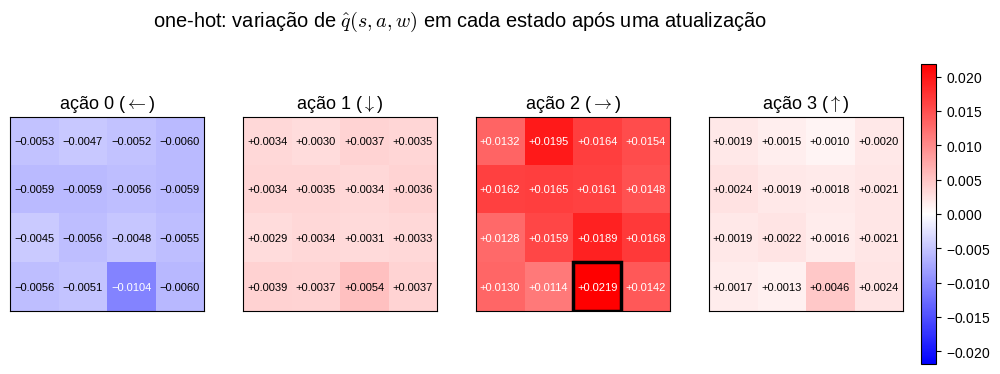

In [ ]:
dQ_one_hot = one_update(Phi_one_hot, params)                                    # Uma atualização com phi(s) one-hot
plot_update_effect(dQ_one_hot, ENV_ID, updated=(14, 2), fmt="+.4f", title="one-hot")

erro TD: -0.9777
estimativa do par atualizado: 0.0223 -> 0.0573


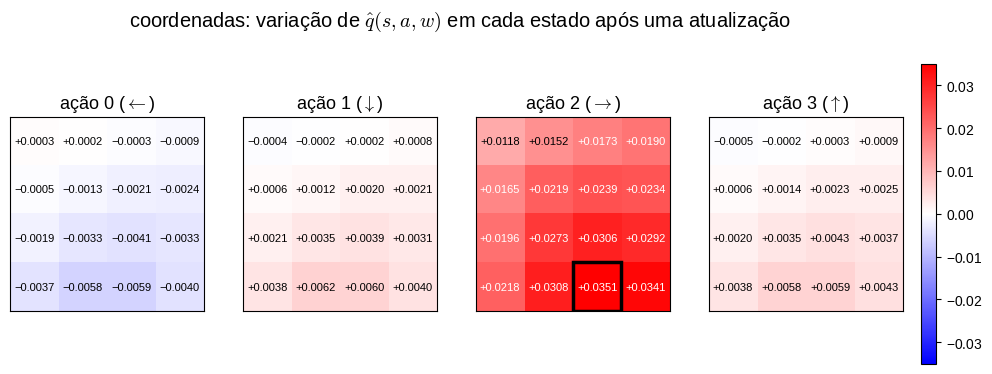

In [ ]:
dQ_coords = one_update(Phi_coords, params)                                      # Uma atualização com phi(s) por coordenadas
plot_update_effect(dQ_coords, ENV_ID, updated=(14, 2), fmt="+.4f", title="coordenadas")

### Simulação

As células abaixo treinam os dois agentes na configuração do exemplo, cada um com um ambiente (`train_env`) e um agente novos. A semente fixa os pesos iniciais da rede e todos os sorteios do agente, e o FrozenLake sem escorregamento é determinístico: com a mesma semente, a execução é reprodutível.

In [ ]:
train_env = make_env()                                                          # Ambiente novo para o treinamento
agent_one_hot = SarsaNNAgent(params, Phi_one_hot, seed=SEED)                    # Agente com phi(s) one-hot
history_one_hot = train_agent(agent_one_hot, train_env, params.n_episodes)

Treinando:   0%|          | 0/5000 [00:00<?, ?episódio/s]

In [ ]:
train_env = make_env()                                                          # Ambiente novo para o treinamento
agent_coords = SarsaNNAgent(params, Phi_coords, seed=SEED)                      # Agente com phi(s) por coordenadas
history_coords = train_agent(agent_coords, train_env, params.n_episodes)

Treinando:   0%|          | 0/5000 [00:00<?, ?episódio/s]

As duas redes treinadas, camada por camada:

In [ ]:
print_network(agent_one_hot.net)                                                # Rede do agente com one-hot
print()
print_network(agent_coords.net)                                                 # Rede do agente com coordenadas

Entrada: 16 componentes de phi(s)
Camada oculta 1: 4 neurônios (tanh); pesos (16, 4) e vieses (4,): 68 parâmetros
Saída: 4 neurônios (linear); pesos (4, 4) e vieses (4,): 20 parâmetros
Total de parâmetros em w: 88

Entrada: 2 componentes de phi(s)
Camada oculta 1: 4 neurônios (tanh); pesos (2, 4) e vieses (4,): 12 parâmetros
Saída: 4 neurônios (linear); pesos (4, 4) e vieses (4,): 20 parâmetros
Total de parâmetros em w: 32


Os valores de estado da política aprendida saem das estimativas e da política finais: a média dos valores de ação, ponderada pelas probabilidades da política $\epsilon$-gulosa,

$$v(s) = \sum_a \pi(a \mid s)\, \hat q(s,a,w)$$

In [ ]:
V_one_hot = np.sum(agent_one_hot.Pi * agent_one_hot.Q, axis=1)                  # v(s) = soma_a pi(a|s) q(s,a,w)
V_coords = np.sum(agent_coords.Pi * agent_coords.Q, axis=1)                     # v(s) com coordenadas

### Avaliação da política aprendida

A saída do Sarsa é a política $\epsilon$-gulosa em relação a $\hat q(s,a,w)$ com os parâmetros finais, guardada em `agent.Pi` ao fim do treinamento. `evaluate_policy`, já pronta, mede o desempenho dessa política: executa `n_episodes` episódios (100, por padrão) num ambiente novo, criado por `make_env`, sorteando cada ação com as probabilidades de `agent.Pi`, **sem** atualizar $w$. Ela devolve:

| Métrica | Significado |
|---|---|
| `chegada ao alvo` | proporção dos episódios que terminam no alvo |
| `recompensa total média` | média da recompensa total dos episódios |
| `duração média` | média da duração dos episódios, em passos |

Os sorteios usam um gerador próprio, criado com `seed`.

> **Atenção:** as curvas de `plot_results` vêm do treinamento, em que $w$, e com ele a política, muda a cada passo. Elas mostram como o agente aprendeu; o desempenho da política aprendida é o que `evaluate_policy` mede, com $w$ fixo.

In [ ]:
def evaluate_policy(agent: SarsaNNAgent, n_episodes: int = 100,
                    seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)                                           # Gerador próprio da avaliação
    eval_env = make_env(render_mode=None)                                       # Ambiente novo, com o limite de passos
    returns, lengths, successes = [], [], []

    for _ in range(n_episodes):
        obs, _info = eval_env.reset(seed=int(rng.integers(2**32)))              # s_0
        terminated = truncated = False
        while not (terminated or truncated):
            action = int(rng.choice(agent.n_actions, p=agent.Pi[obs]))          # a ~ pi(.|s), a política aprendida
            obs, _reward, terminated, truncated, info = eval_env.step(action)   # Sem agent.update: w fixo
        returns.append(float(info["episode"]["r"]))                             # Recompensa total
        lengths.append(int(info["episode"]["l"]))                               # Duração
        successes.append(int(terminated and obs == GOAL_STATE))                 # 1 se chegou ao alvo

    return pd.Series({
        "chegada ao alvo": np.mean(successes),
        "recompensa total média": np.mean(returns),
        "duração média": np.mean(lengths),
    })

Nos dois agentes do exemplo:

In [ ]:
pd.DataFrame({"one-hot": evaluate_policy(agent_one_hot),                        # Políticas aprendidas, com w fixo
              "coordenadas": evaluate_policy(agent_coords)})

,one-hot,coordenadas
chegada ao alvo,0.92,0.93
recompensa total média,0.92,0.93
duração média,6.31,6.31


### Visualização

As figuras vêm das funções do `rl_utils_lab10`, importadas no início do notebook:

| Função | Descrição |
|---|---|
| `plot_results` | recompensa total, duração, taxa de exploração, chegada ao alvo e erro TD por episódio, com a média móvel de `STATS_BUFFER_LENGTH` episódios |
| `simulate_trajectory` | executa um episódio num ambiente próprio e devolve a trajetória; por padrão, a trajetória gulosa (definida abaixo) |
| `plot_trajectory` | o caminho sobre a grade, com buracos ou penhasco em vermelho e o alvo em verde |
| `show_one_episode` | a animação de um episódio com a política aprendida ($\epsilon$-gulosa), exploração incluída |
| `plot_tabular` | mapas de calor de $\hat q(s,a,w)$, $\pi(a \mid s)$ ou $v(s)$, escolhidos pelo argumento `kind` |
| `plot_policy_distributions` | as probabilidades das quatro ações em cada estado |
| `plot_comparison` | as médias móveis de várias execuções num só gráfico, com legenda (usada na tarefa) |
| `plot_update_effect` | a variação de $\hat q(s,a,w)$ em cada estado após uma atualização |
| `print_network` | as camadas da rede e o número de parâmetros |

> **Atenção:** cada mapa de calor calcula a escala de cores a partir dos próprios valores, e a mesma cor pode representar números diferentes em figuras diferentes. Para comparar figuras, use os números anotados nas células.

<details>
<summary><b>Detalhes:</b> gráficos lado a lado</summary>

- `plot_comparison`, `plot_trajectory` e `plot_tabular` aceitam o argumento `ax`, o painel da figura em que o gráfico é desenhado. Com `ax`, elas não chamam `plt.show()`, e a figura é exibida uma vez só, ao final. Para as curvas de chegada ao alvo e de duração lado a lado:

      fig, axs = plt.subplots(1, 2, figsize=(18, 5))
      plot_comparison(histories, metric="successes", ax=axs[0])
      plot_comparison(histories, metric="lengths", ax=axs[1])
      plt.tight_layout()
      plt.show()

  em que `histories` é um dicionário que associa o rótulo de cada configuração (o texto da legenda) ao histórico devolvido por `train_agent`.

</details>

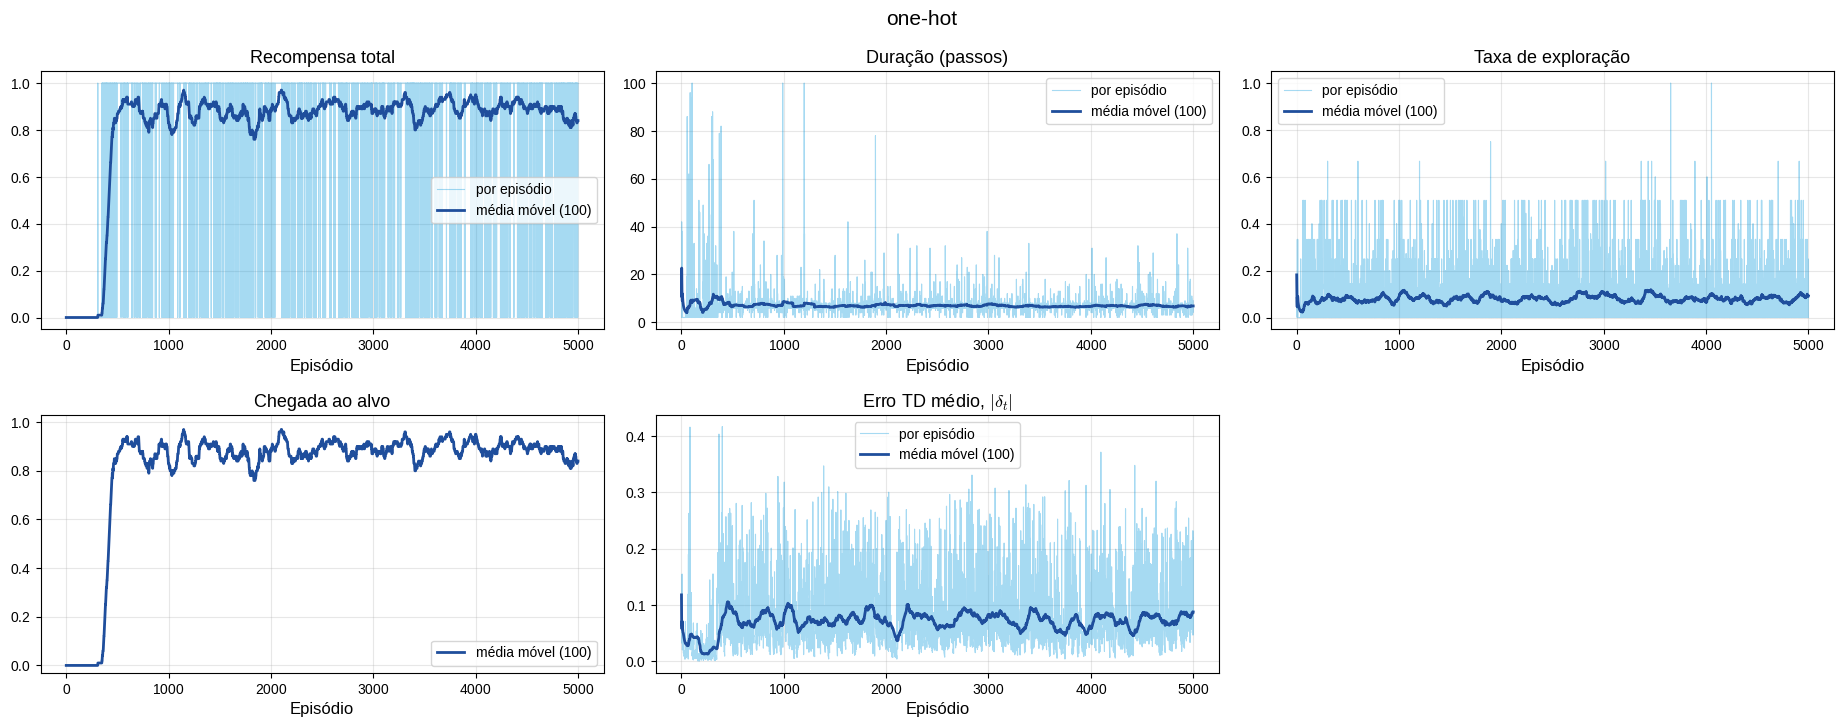

In [ ]:
_ = plot_results(                                                               # Métricas do agente com one-hot
    history_one_hot.returns, history_one_hot.lengths, history_one_hot.exploration_rates,
    history_one_hot.successes, window=STATS_BUFFER_LENGTH, td_errors=history_one_hot.td_errors,
    title="one-hot")

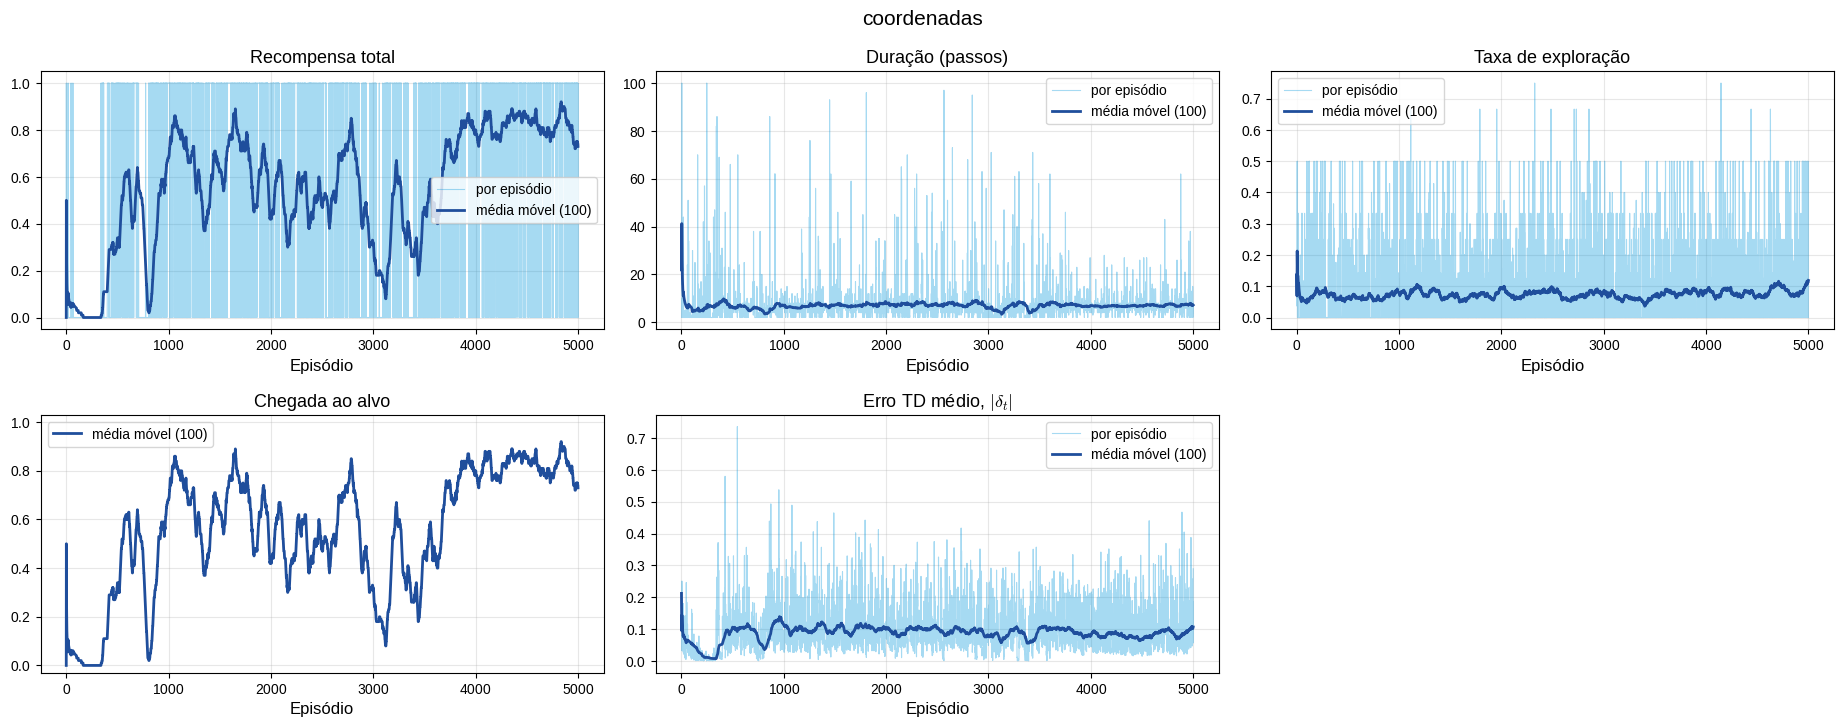

In [ ]:
_ = plot_results(                                                               # Métricas do agente com coordenadas
    history_coords.returns, history_coords.lengths, history_coords.exploration_rates,
    history_coords.successes, window=STATS_BUFFER_LENGTH, td_errors=history_coords.td_errors,
    title="coordenadas")

**Trajetória gulosa:** a trajetória obtida executando, em cada estado, a ação mais provável da política $\epsilon$-gulosa aprendida, $\arg\max_a \hat q(s,a,w)$.

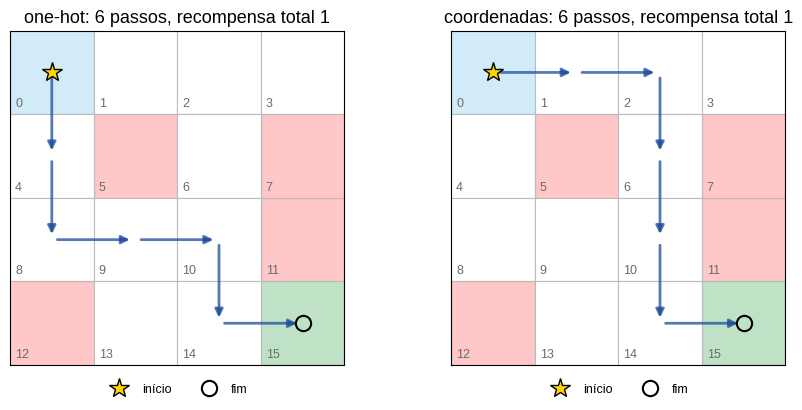

In [ ]:
agents = {"one-hot": agent_one_hot, "coordenadas": agent_coords}                # Os dois agentes do exemplo
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (name, agent_exp) in zip(axs, agents.items()):
    states, actions, rewards = simulate_trajectory(agent_exp, ENV_ID)           # Trajetória gulosa (sem exploração)
    title = f"{name}: {len(actions)} passos, recompensa total {sum(rewards):.0f}"
    plot_trajectory(ENV_ID, states, title=title, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
show_one_episode(agent_one_hot.policy, ENV_ID, seed=SEED)                       # Animação com a política epsilon-gulosa

In [ ]:
show_one_episode(agent_coords.policy, ENV_ID, seed=SEED)                        # Animação com a política epsilon-gulosa

> **Atenção:** nos mapas de calor de $\hat q(s,a,w)$ e de $v(s)$, os estados terminais aparecem em cinza, com o valor $0$: o valor verdadeiro de um estado terminal, $v(s) = q(s,\cdot) = 0$, mascarado em substituição à saída da rede neural nesses estados. As saídas da rede continuam em `agent.Q`.

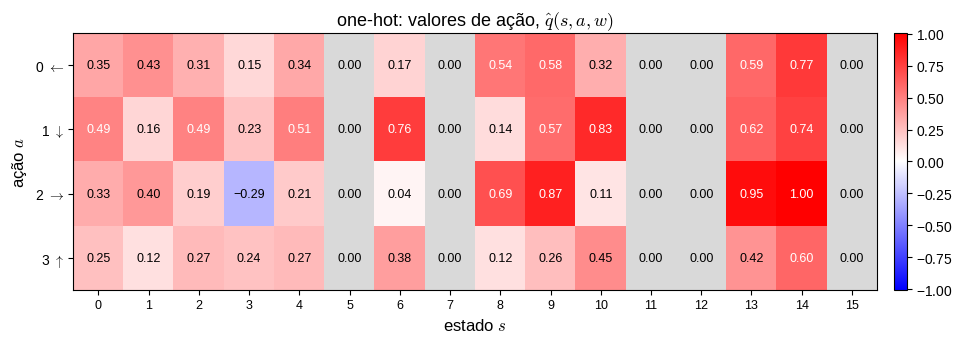

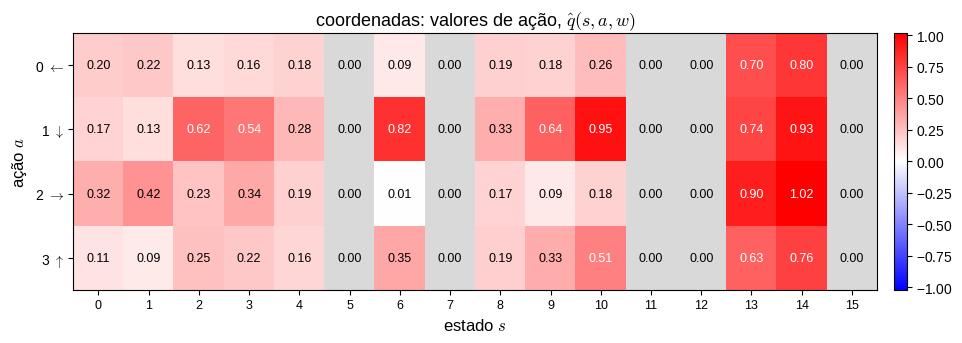

In [ ]:
_ = plot_tabular(agent_one_hot.Q, kind="Q", env_id=ENV_ID,
                 title=r"one-hot: valores de ação, $\hat q(s,a,w)$")            # q: ndarray (n_estados, n_acoes)
_ = plot_tabular(agent_coords.Q, kind="Q", env_id=ENV_ID,
                 title=r"coordenadas: valores de ação, $\hat q(s,a,w)$")

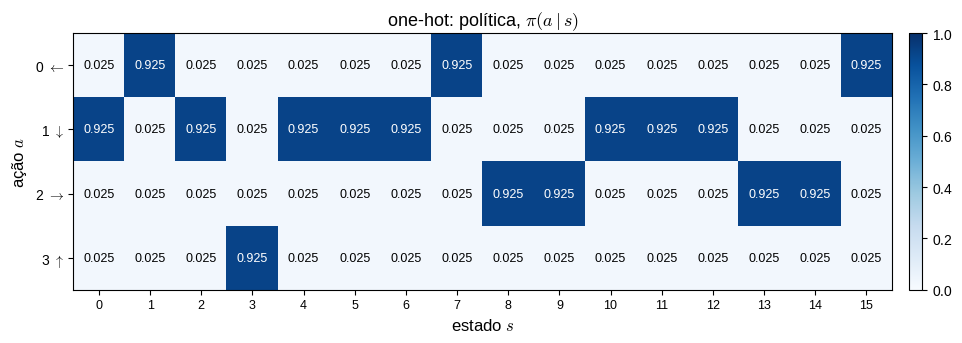

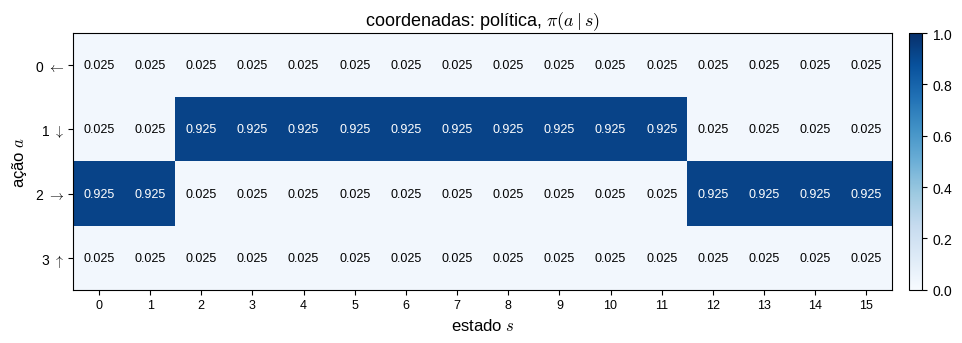

In [ ]:
_ = plot_tabular(agent_one_hot.Pi, kind="Pi", env_id=ENV_ID,
                 title=r"one-hot: política, $\pi(a \mid s)$")                   # pi: ndarray (n_estados, n_acoes)
_ = plot_tabular(agent_coords.Pi, kind="Pi", env_id=ENV_ID,
                 title=r"coordenadas: política, $\pi(a \mid s)$")

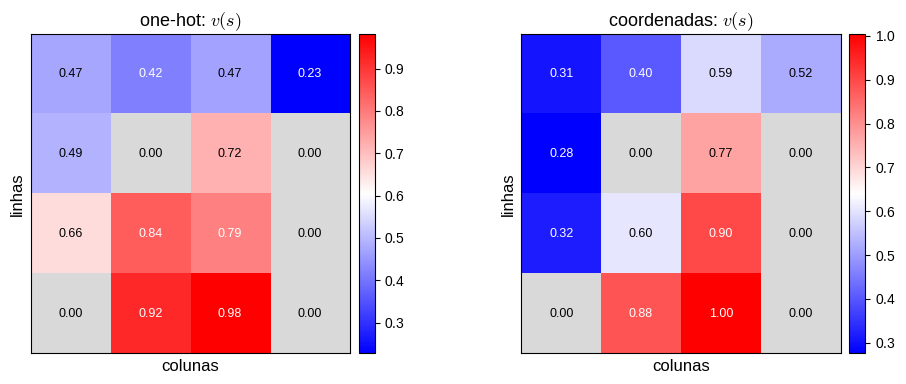

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
plot_tabular(V_one_hot, kind="V", env_id=ENV_ID, center_zero=False, ax=axs[0],
             title=r"one-hot: $v(s)$")                                          # v: ndarray (n_estados,)
plot_tabular(V_coords, kind="V", env_id=ENV_ID, center_zero=False, ax=axs[1],
             title=r"coordenadas: $v(s)$")
plt.tight_layout()
plt.show()

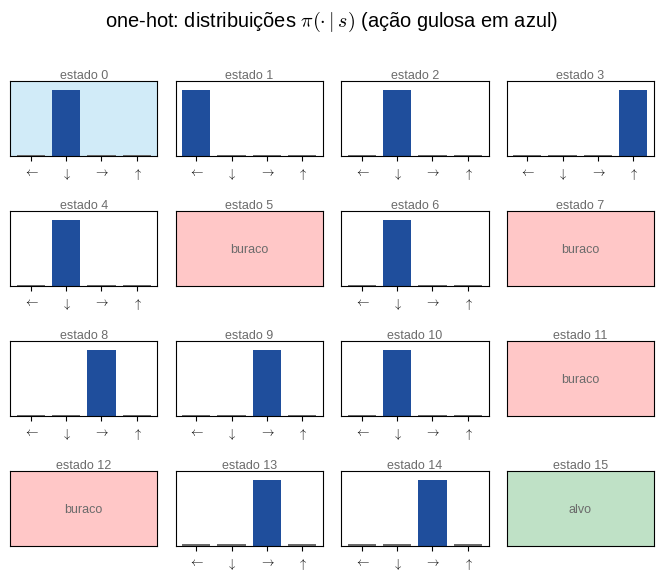

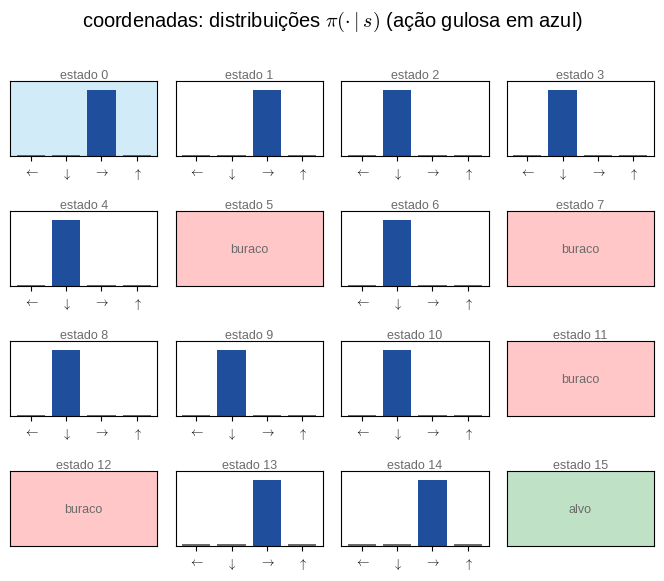

In [ ]:
plot_policy_distributions(agent_one_hot.Pi, ENV_ID, title="one-hot")            # pi(.|s) em cada estado
plot_policy_distributions(agent_coords.Pi, ENV_ID, title="coordenadas")

# Tarefa (em trios):

### 🧭 Guia de Estudo e Apresentação (Laboratório 10 - SARSA com Redes Neurais)

<div style="padding: 12px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 15px;">
  <h4 style="color: #27ae60; margin-top: 0;">🟢 O QUE VOCÊ DEVE DETALHAR E DESTACAR (Fale com confiança):</h4>
  <ul style="color: #1e824c; line-height: 1.6;">
    <li><b>A transição de Tabular para Aproximação:</b> Nos Labs 7 a 9, guardávamos os valores em uma tabela de tamanho fixo. No Lab 10, usamos uma Rede Neural ($) com pesos $ para prever (s, a; w)$.</li>
    <li><b>Generalização vs Memória:</b> No modo tabular, atualizar um estado $ não afeta nenhum outro. Na rede neural com pesos compartilhados, atualizar um par $ propaga gradientes que <b>alteram as estimativas de outros estados e ações</b>!</li>
    <li><b>Dois tipos de características (Phi):</b>
      <ul>
        <li><b>One-Hot:</b> Cada estado tem seu próprio neurônio de entrada (16 entradas no FrozenLake, 48 no CliffWalking). Não há noção de proximidade espacial entre estados.</li>
        <li><b>Coordenadas Normalizadas:</b> Apenas 2 entradas por estado: [linha normalizada, coluna normalizada] em [-1, 1]. A rede aprende que estados vizinhos são parecidos no espaço!</li>
      </ul>
    </li>
  </ul>
</div>

<div style="padding: 12px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <h4 style="color: #c0392b; margin-top: 0;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHAS DA BANCA (Atenção redobrada):</h4>
  <ul style="color: #962d22; line-height: 1.6;">
    <li><b>Por que na seção 'Uma atualização' todas as 64 estimativas mudaram?</b> Porque na rede neural os pesos $ conectam as entradas a todas as saídas. Ao dar um passo de gradiente (\_fit$), os pesos de toda a rede são atualizados, afetando mesmo os estados que não foram visitados!</li>
    <li><b>O 'Esquecimento Catastrófico' (Catastrophic Forgetting):</b> Se a rede neural atualizar demais um estado ruim (ex: cair no penhasco), os pesos podem mudar tanto que ela 'desaprende' o caminho seguro que tinha aprendido antes.</li>
    <li><b>Por que o alvo usa \_fit(x, y)$ com todas as outras ações inalteradas?</b> Porque no scikit-learn o $ prevê todas as 4 ações juntas. Para que o erro só penalize a ação executada $, mantemos as previsões antigas das outras ações e alteramos apenas a posição $ para o alvo TD!</li>
  </ul>
</div>


Responda no próprio notebook. Cada item tem uma seção **Resposta**, com:

- uma célula de código, para os experimentos, as figuras e as tabelas;
- uma célula de texto, com **uma resposta por pergunta**, identificada pelo mesmo rótulo: (a), (b), ...

Acrescente células se precisar, mas não apague nem reordene os enunciados.

O item 0 explora o exemplo pronto no FrozenLake. Nos itens 1 e 2, o objetivo é resolver o CliffWalking com o Sarsa com aproximação de função, com as duas escolhas de $\phi(s)$. Nesses itens, a configuração é livre: a arquitetura da rede e os hiperparâmetros da rede e do Sarsa podem ser escolhidos à vontade; só a semente é fixa, `SEED = 42`, para que os resultados sejam reprodutíveis.

**Configuração base (baseline):** a do exemplo, usada no item 0.

| Parâmetro | Valor |
|---|---|
| ambiente | `FrozenLake-v1` $4 \times 4$, sem escorregamento, com `MAX_EPISODE_STEPS = 100` |
| vetores de características | one-hot, com 16 componentes, e coordenadas normalizadas, com 2: um agente com cada |
| rede | uma camada oculta com 4 neurônios $\tanh$ e saída linear |
| otimizador | Adam (`solver = "adam"`) |
| taxa de aprendizado, $\alpha$ | `learning_rate = 0.01` |
| fator de desconto, $\gamma$ | `discount_factor = 0.9` |
| parâmetro $\epsilon$ | `epsilon = 0.1`, fixo durante o treinamento |
| número de episódios, $N$ | `n_episodes = 5000` |
| janela das médias móveis | `STATS_BUFFER_LENGTH = 100` episódios |
| semente | `SEED = 42`, com ambiente (`make_env`) e agente novos em cada execução |

**Mostrar**

- **Figuras:**
  - item 0: as figuras das seções **Uma atualização** e **Visualização**;
  - itens 1 e 2, para a configuração encontrada: as mesmas figuras da seção **Visualização**, ou seja, as curvas de `plot_results`, a trajetória gulosa (`plot_trajectory`), a animação de um episódio (`show_one_episode`), os mapas de calor de $\hat q(s,a,w)$, $\pi(a \mid s)$ e $v(s)$ (`plot_tabular`) e as distribuições $\pi(\cdot \mid s)$ (`plot_policy_distributions`);
  - itens 1 e 2, para o estudo de hiperparâmetros: as curvas de chegada ao alvo, de duração e de erro TD dos três agentes, sobrepostas e com legenda (`plot_comparison`), e a trajetória gulosa de cada agente (`plot_trajectory`).
- **Tabelas:** nos itens 1 e 2, a tabela de hiperparâmetros da configuração encontrada e a tabela do estudo de hiperparâmetros, com as métricas de `evaluate_policy` de cada valor.
- **Discussão:** uma resposta curta por pergunta, na célula de texto da **Resposta**.

**Entregáveis**

- Um notebook (`.ipynb`) por laboratório da Unidade 2, entregue ao fim da unidade, com a tarefa respondida nas seções **Resposta**. Nesta unidade não há relatório em PDF.
- O notebook deve **executar do início ao fim sem erros** em um kernel novo (*Restart & Run All*), com as saídas exibidas correspondendo a essa execução. Notebooks que não executarem por completo serão penalizados.
- A entrega é **única por grupo**, com os integrantes identificados no início do notebook.

## 0. Exemplo: FrozenLake

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 0 (FrozenLake):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>(a) Quantas estimativas mudaram em uma atualização?</b>
      <ul>
        <li>Na <b>Rede Neural:</b> Todas as 64 estimativas (16 estados $	imes$ 4 ações) mudaram! Os pesos $ são compartilhados por todos os neurônios, gerando acoplamento entre todos os estados.</li>
        <li>No <b>Sarsa Tabular:</b> Apenas 1 estimativa mudaria (a célula [14, 2]$).</li>
      </ul>
    </li>
    <li><b>Diferença espacial nas coordenadas:</b> Nas coordenadas normalizadas, os estados vizinhos geograficamente ao estado 14 sofreram alterações muito maiores, comprovando a <b>generalização espacial</b>.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">A generalização é sempre boa? <b>Resposta:</b> Não necessariamente! Se dois estados vizinhos tiverem valores muito opostos (ex: o estado 25 que é chão seguro e o estado 37 que é penhasco com -100), a aproximação suave por coordenadas pode 'borrar' o penhasco nos estados seguros se a rede não tiver capacidade não-linear suficiente.</p>
</div>

**Experimento:** execute a seção **Experimento**, sem nada a implementar:
  - a atualização isolada da seção **Uma atualização**, com cada vetor de características;
  - o treinamento dos dois agentes do exemplo;
  - a avaliação das políticas aprendidas e
  - a visualização.

**Perguntas:**

- **(a)** Quantas estimativas $\hat q(s,a,w)$ mudaram na atualização da seção **Uma atualização**, com cada vetor de características? E quantas mudariam numa atualização do Sarsa tabular do Laboratório 7? Explique a diferença.
- **(b)** Os estados terminais do FrozenLake (os buracos e o alvo) nunca são o $s_t$ de uma atualização. Que valores $\hat q(s,a,w)$ cada rede treinada atribui a eles? Essas predições são utilizadas na construção do alvo TD? Qual o valor de estado em um estado terminal? Qual o valor de ação de um estado terminal?
- **(c)** Com o aumento do tamanho da grade, qual a potencial vantagem da representação por coordenadas comparada com a codificação 1-de-c (*one-hot-encoding*)?

### Resposta

In [ ]:
# Contagem de estimativas q(s,a,w) que sofreram alteração após 1 passo (|dQ| > 0)
n_changed_one_hot = int(np.sum(np.abs(dQ_one_hot) > 0))
n_changed_coords = int(np.sum(np.abs(dQ_coords) > 0))
print(f"Estimativas alteradas ( de {dQ_one_hot.size} pares (s,a) ):")
print(f" - One-hot: {n_changed_one_hot}")
print(f" - Coordenadas: {n_changed_coords}\n")

# Valores preditos pelas redes treinadas nos estados terminais (buracos: 5, 7, 11, 12; alvo: 15)
estados_terminais = [5, 7, 11, 12, 15]
df_terminais_oh = pd.DataFrame(
    agent_one_hot.Q[estados_terminais],
    index=[f"s={s}" for s in estados_terminais],
    columns=[f"a={a}" for a in range(4)]
)
df_terminais_coords = pd.DataFrame(
    agent_coords.Q[estados_terminais],
    index=[f"s={s}" for s in estados_terminais],
    columns=[f"a={a}" for a in range(4)]
)

print("Predições q(s,a,w) nos estados terminais (One-Hot):")
display(df_terminais_oh.round(4))

print("\nPredições q(s,a,w) nos estados terminais (Coordenadas):")
display(df_terminais_coords.round(4))

Estimativas alteradas ( de 64 pares (s,a) ):
 - One-hot: 64
 - Coordenadas: 64

Predições q(s,a,w) nos estados terminais (One-Hot):


,a=0,a=1,a=2,a=3
s=5,0.3722,0.4968,0.3025,0.3994
s=7,0.4148,0.3954,0.3944,0.3588
s=11,0.3646,0.4602,0.2557,0.2611
s=12,0.2382,0.2706,0.0141,0.2232
s=15,0.3693,0.2960,0.2576,0.2517



Predições q(s,a,w) nos estados terminais (Coordenadas):


,a=0,a=1,a=2,a=3
s=5,0.1586,0.4041,0.1651,0.2030
s=7,0.1495,0.6869,0.2135,0.2986
s=11,0.5354,0.8083,0.7088,0.5591
s=12,0.5549,0.2870,0.7723,0.3511
s=15,0.8646,0.8795,1.1579,0.7625


- **(a)**

Na atualização da seção "Uma atualização", todas as 64 estimativas $\hat q(s,a,w)$, ou seja, os 16 estados $\times$ 4 ações mudaram, tanto com o vetor de características *one-hot* quanto com o de coordenadas normalizadas, sendo que nos mapas de calor, com arredondamento em 4 casas decimais, a variação mais expressiva aparece na ação atualizada $a_t = 2$, especialmente no estado visitado $s_t = 14$ e, no caso das coordenadas, nos estados vizinhos a ele. Já no Sarsa tabular do Lab 7, apenas 1 estimativa mudaria, a entrada $Q(14, 2)$ da tabela. Essa diferença acontece porque, na abordagem tabular, cada par de valor de estado e ação é armazenado de forma independente. Na rede neural, os parâmetros $w$, que são pesos e vieses das camadas oculta e de saída, são compartilhados por todos os estados e ações. Assim, alterar os pesos da camada oculta para reduzir o erro em $(14, 2)$ modifica as ativações internas da rede e propaga variações para todos os 64 pares.

- **(b)**

As redes treinadas atribuem valores positivos não nulos para $\hat q(s,a,w)$ nos estados terminais $\{5, 7, 11, 12, 15\}$, pois os pesos de entrada exclusivos desses estados não são atualizados, mas as saídas mudam devido aos vieses e pesos da camada oculta ajustados pelos outros estados Já com coordenadas, os valores crescem conforme a proximidade geométrica ao alvo, por conta da interpolação contínua da grade. Essas predições **não são utilizadas** na construção do alvo TD: quando `terminated=True`, o método `get_target_value` devolve diretamente $\bar q_t = r_{t+1}$, ignorando $\hat q(s_{t+1}, a_{t+1}, w_t)$. Por definição, em um estado terminal $s$, os valores de estado e de ação são iguais a zero para todas as ações.

- **(c)**

Com o aumento do tamanho da grade, a representação por coordenadas normalizadas mantém a entrada da rede fixa em apenas dois componentes, linha e coluna em $[-1, 1]$, enquanto a codificação 1-de-c (*one-hot-encoding*) cresce linearmente com o número de células ($|\mathcal{S}|$ componentes), exigindo muito mais parâmetros na primeira camada. Além da economia de parâmetros, as coordenadas oferecem generalização espacial, como estados próximos na grade têm vetores $\phi(s)$ próximos, o aprendizado obtido ao visitar uma célula atualiza automaticamente as estimativas de células vizinhas ainda pouco visitadas, acelerando o aprendizado em grades grandes.

## 1. CliffWalking com one-hot

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 1 (CliffWalking One-Hot):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Dimensão da entrada:</b> Vetor $\phi(s)$ de 48 posições (uma para cada estado).</li>
    <li><b>Comportamento do Sarsa NN:</b> Como o SARSA continua sendo <i>on-policy</i>, ele aprende a rota conservadora contornando pelo topo da grade para se afastar do penhasco.</li>
    <li><b>Convergência:</b> Mostre a curva de recompensa e o decaimento do erro TD ao longo dos episódios.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Por que usar rede neural com One-Hot se a tabela já resolvia? <b>Resposta:</b> O One-Hot serve como prova de conceito e validação para testar se a arquitetura neural é capaz de aprender sem overfitting ou instabilidade antes de passarmos para representações compactas e contínuas.</p>
</div>

Os itens 1 e 2 usam o `CliffWalking-v1`, do [Gymnasium](https://gymnasium.farama.org/environments/toy_text/cliff_walking/), o mesmo dos laboratórios 7 a 9:

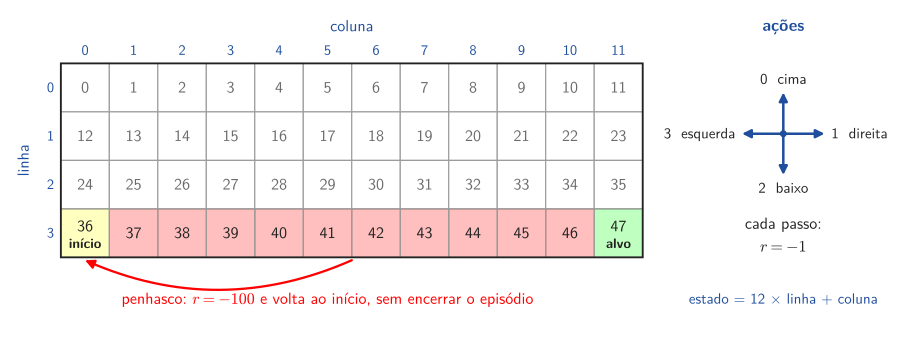

In [ ]:
show_figure("mapa_cliffwalking")                                                # Mapa do CliffWalking

- **Estado:** o índice da célula, `12 * linha + coluna`.
- **Ações:** quatro: 0 (cima), 1 (direita), 2 (baixo) e 3 (esquerda).
- **Recompensa:** $-1$ por passo. Entrar no penhasco custa $-100$ e devolve o agente a $s_0 = 36$, **sem** encerrar o episódio.
- **Fim do episódio:** o alvo, o estado 47, é o único estado terminal. O episódio também termina ao atingir o limite de passos: use 500, como nos laboratórios 7 a 9.

**Experimento:** resolva o `CliffWalking-v1` com o Sarsa com aproximação de função e $\phi(s)$ one-hot, com 48 componentes:

1. faça no código do exemplo as alterações necessárias para o CliffWalking (ambiente, estado-alvo, número de estados e vetor de características);
2. encontre uma configuração que resolva o ambiente. A arquitetura da rede e os hiperparâmetros da rede e do Sarsa são livres; só a semente é fixa, `SEED = 42`.

Neste laboratório considere que o ambiente está resolvido quando a política aprendida, medida por `evaluate_policy`, chega ao alvo em pelo menos 90% dos episódios, com duração média de no máximo 30 passos (o caminho mais curto tem 13 passos, e o caminho seguro, longe do penhasco, 17).

Descreva a configuração encontrada numa tabela como a abaixo, com o valor de cada hiperparâmetro, e mostre, para essa configuração, as métricas de `evaluate_policy` e as mesmas figuras da seção **Visualização**:

| hiperparâmetro | valor |
|---|---|
| camadas ocultas e neurônios (`hidden_layer_sizes`) | |
| ativação (`activation`) | |
| otimizador (`solver`) | |
| taxa de aprendizado, $\alpha$ (`learning_rate`) | |
| fator de desconto, $\gamma$ (`discount_factor`) | |
| parâmetro $\epsilon$ (`epsilon`) | |
| número de episódios, $N$ (`n_episodes`) | |

**Estudo de hiperparâmetros:** escolha um dos hiperparâmetros abaixo e treine três agentes, um com cada valor, com os demais hiperparâmetros iguais aos da configuração encontrada:

| hiperparâmetro | valores |
|---|---|
| taxa de aprendizado, $\alpha$ (`learning_rate`) | 0.001, 0.003 e 0.01 |
| parâmetro $\epsilon$ (`epsilon`) | 0.01, 0.1 e 0.3 |
| camadas ocultas e neurônios (`hidden_layer_sizes`) | `(8,)`, `(32,)` e `(128,)` |
| fator de desconto, $\gamma$ (`discount_factor`) | 0.7, 0.9 e 0.99 |

Mostre as curvas de chegada ao alvo, de duração e de erro TD dos três agentes, sobrepostas e com legenda (`plot_comparison`), a trajetória gulosa de cada agente (`plot_trajectory`) e uma tabela com as métricas de `evaluate_policy` de cada valor.

**Pergunta:**

- **(a)** No estudo, como cada valor afetou as curvas de treinamento e a política aprendida?

### Resposta

In [ ]:
ENV_ID = "CliffWalking-v1"
MAX_EPISODE_STEPS = 500
GOAL_STATE = 47

In [ ]:
def make_env(render_mode: Optional[str] = "rgb_array") -> gym.Env:
    env = gym.make(ENV_ID, render_mode=render_mode, max_episode_steps=MAX_EPISODE_STEPS)
    return RecordEpisodeStatistics(env, buffer_length=STATS_BUFFER_LENGTH)

env_cw = make_env()
Phi_cw_one_hot = one_hot_features(env_cw.observation_space.n)

In [ ]:
# COnfigurando a entrada
params_cw_oh = Params(
    n_states=env_cw.observation_space.n,
    n_actions=env_cw.action_space.n,
    n_episodes=1500,
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    learning_rate=0.003,
    discount_factor=0.99,
    epsilon=0.1,
)

In [ ]:
train_env = make_env()
agent_cw_oh = SarsaNNAgent(params_cw_oh, Phi_cw_one_hot, seed=SEED)
history_cw_oh = train_agent(agent_cw_oh, train_env, params_cw_oh.n_episodes)

Treinando:   0%|          | 0/1500 [00:00<?, ?episódio/s]

In [ ]:
eval_cw_oh = evaluate_policy(agent_cw_oh)
print(f' Avaliação da Configuração Encontrada (One-Hot)')
display(pd.DataFrame({"CliffWalking (one-hot)": eval_cw_oh}))

 Avaliação da Configuração Encontrada (One-Hot)


,CliffWalking (one-hot)
chegada ao alvo,1.00
recompensa total média,-26.40
duração média,18.48


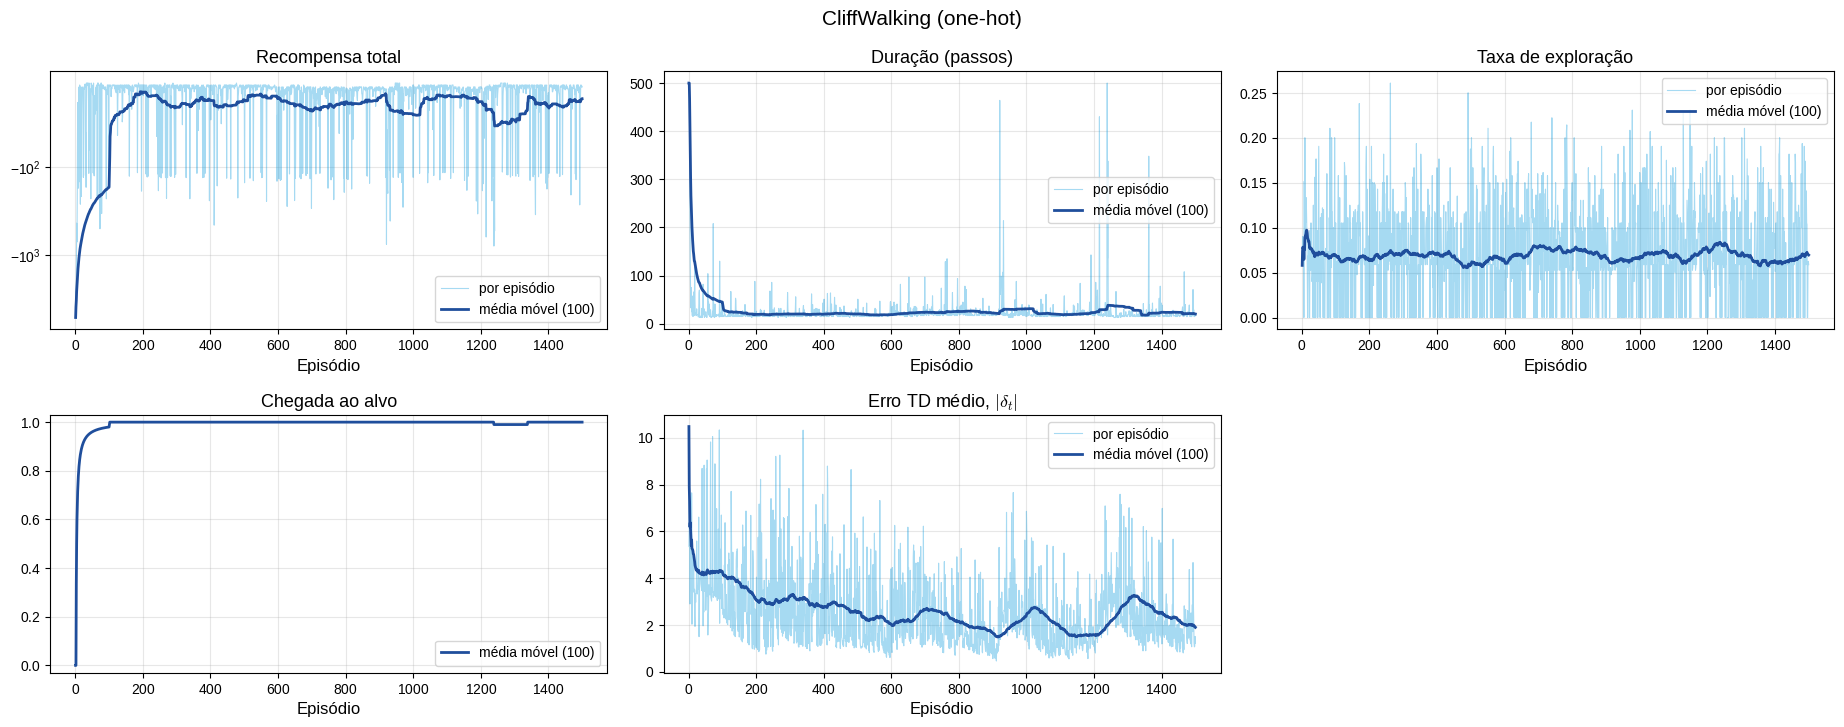

In [ ]:
_ = plot_results(
    history_cw_oh.returns, history_cw_oh.lengths, history_cw_oh.exploration_rates,
    history_cw_oh.successes, window=STATS_BUFFER_LENGTH, td_errors=history_cw_oh.td_errors,
    title="CliffWalking (one-hot)"
)

states_oh, actions_oh, rewards_oh = simulate_trajectory(agent_cw_oh, ENV_ID)


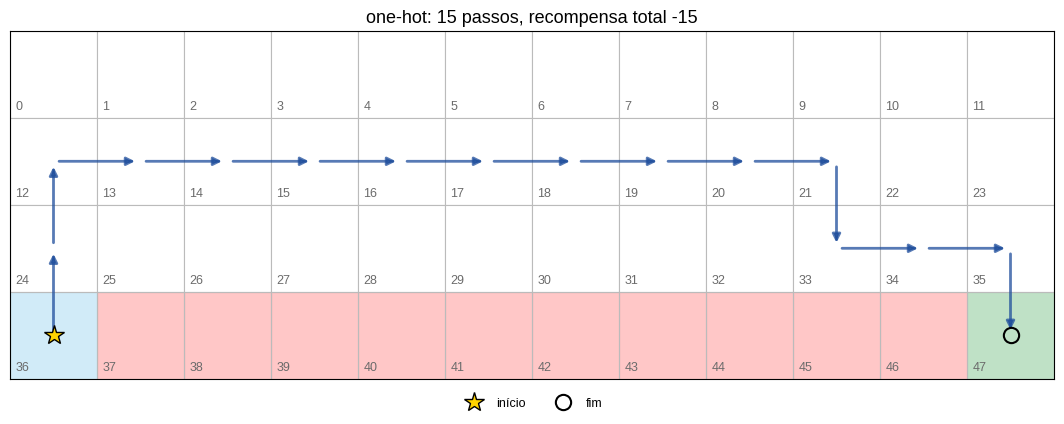

In [ ]:
plot_trajectory(
    ENV_ID, states_oh,
    title=f"one-hot: {len(actions_oh)} passos, recompensa total {sum(rewards_oh):.0f}"
)
show_one_episode(agent_cw_oh.policy, ENV_ID, seed=SEED)

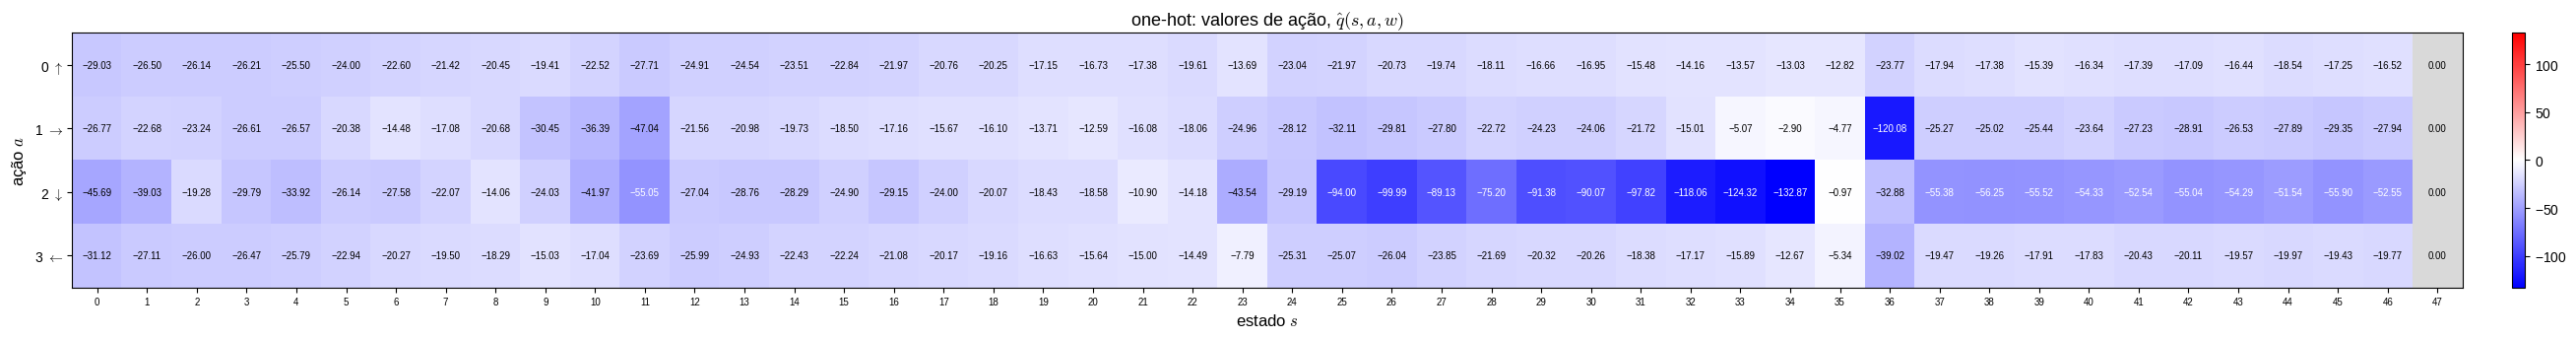

<Axes: title={'center': 'one-hot: valores de ação, $\\hat q(s,a,w)$'}, xlabel='estado $s$', ylabel='ação $a$'>

In [ ]:
V_cw_oh = np.sum(agent_cw_oh.Pi * agent_cw_oh.Q, axis=1)
plot_tabular(agent_cw_oh.Q, kind="Q", env_id=ENV_ID, title=r"one-hot: valores de ação, $\hat q(s,a,w)$")

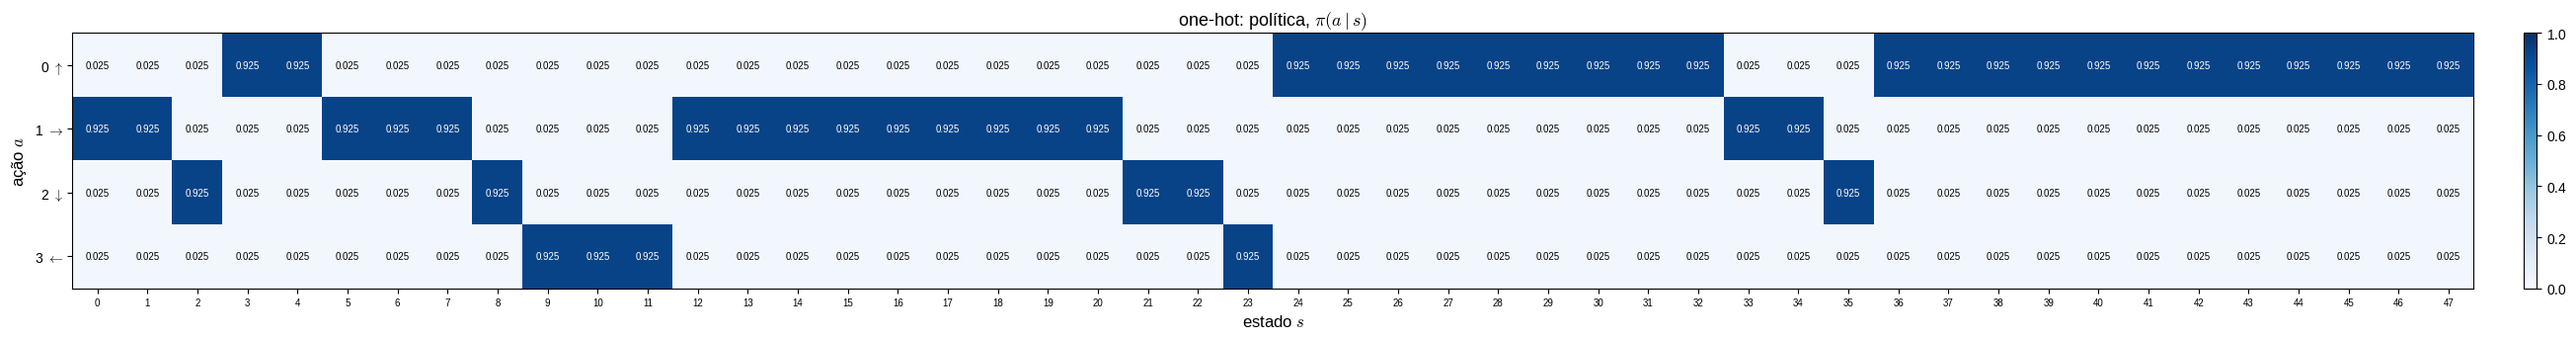

<Axes: title={'center': 'one-hot: política, $\\pi(a \\mid s)$'}, xlabel='estado $s$', ylabel='ação $a$'>

In [ ]:
plot_tabular(agent_cw_oh.Pi, kind="Pi", env_id=ENV_ID, title=r"one-hot: política, $\pi(a \mid s)$")

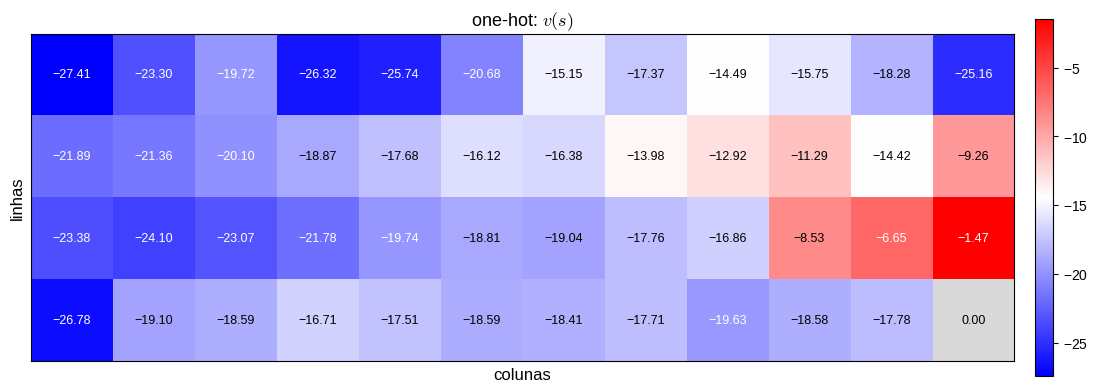

<Axes: title={'center': 'one-hot: $v(s)$'}, xlabel='colunas', ylabel='linhas'>

In [ ]:
plot_tabular(V_cw_oh, kind="V", env_id=ENV_ID, center_zero=False, title=r"one-hot: $v(s)$")

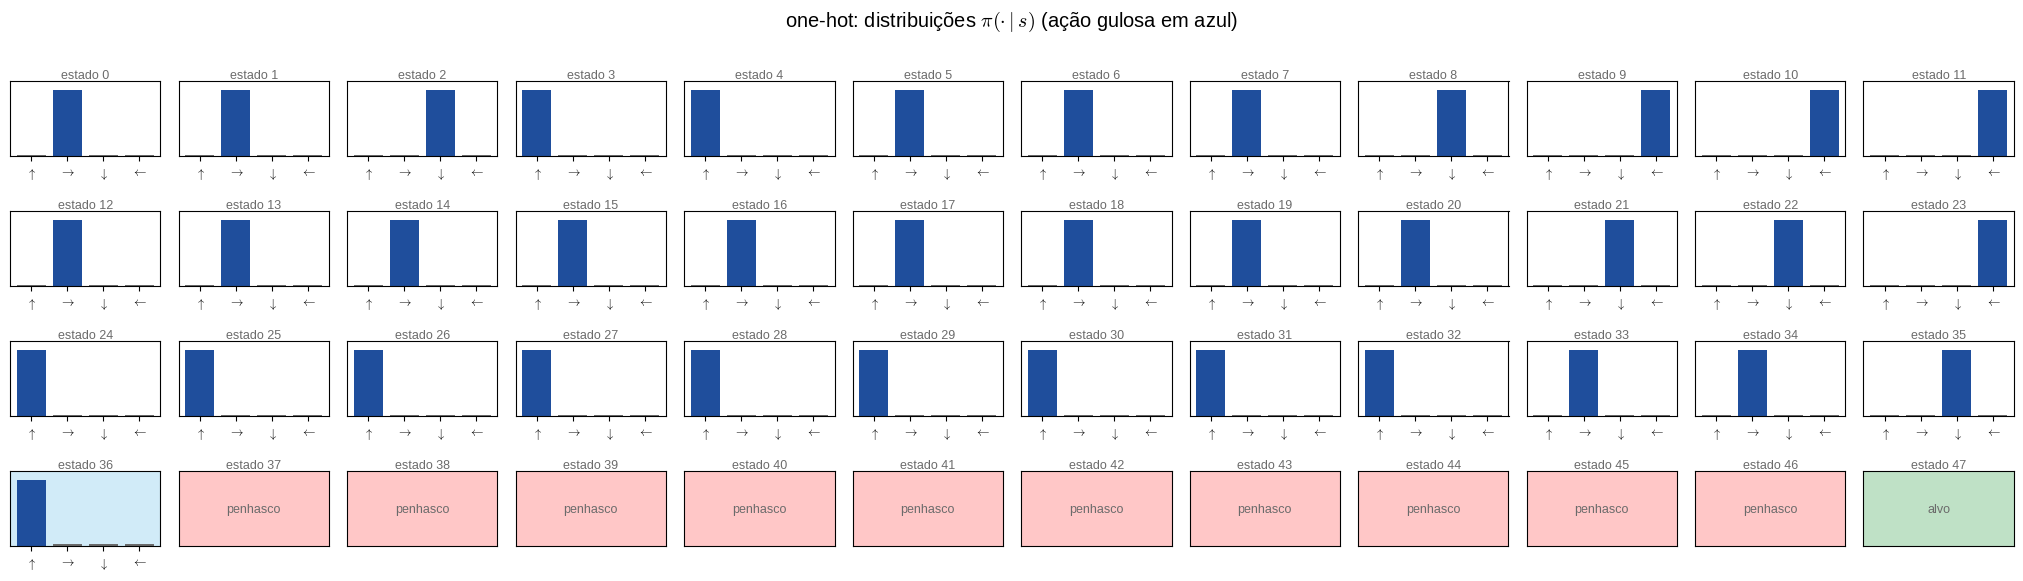

In [ ]:
plot_policy_distributions(agent_cw_oh.Pi, ENV_ID, title="one-hot")

In [ ]:
# Variando epsilon
eps_values = [0.01, 0.1, 0.3]
histories_study_oh = {}
agents_study_oh = {}
evals_study_oh = {}

for eps in eps_values:
    label = f"epsilon = {eps}"
    p_study = params_cw_oh._replace(epsilon=eps)
    t_env = make_env()
    ag = SarsaNNAgent(p_study, Phi_cw_one_hot, seed=SEED)
    hist = train_agent(ag, t_env, p_study.n_episodes)
    histories_study_oh[label] = hist
    agents_study_oh[label] = ag
    evals_study_oh[label] = evaluate_policy(ag)

print(f'Tabela do Estudo de Hiperparâmetros (One-Hot: variação de epsilon)')
display(pd.DataFrame(evals_study_oh))

Treinando:   0%|          | 0/1500 [00:00<?, ?episódio/s]

Treinando:   0%|          | 0/1500 [00:00<?, ?episódio/s]

Treinando:   0%|          | 0/1500 [00:00<?, ?episódio/s]

Tabela do Estudo de Hiperparâmetros (One-Hot: variação de epsilon)


,epsilon = 0.01,epsilon = 0.1,epsilon = 0.3
chegada ao alvo,1.00,1.00,1.00
recompensa total média,-17.98,-26.40,-39.32
duração média,16.99,18.48,25.46


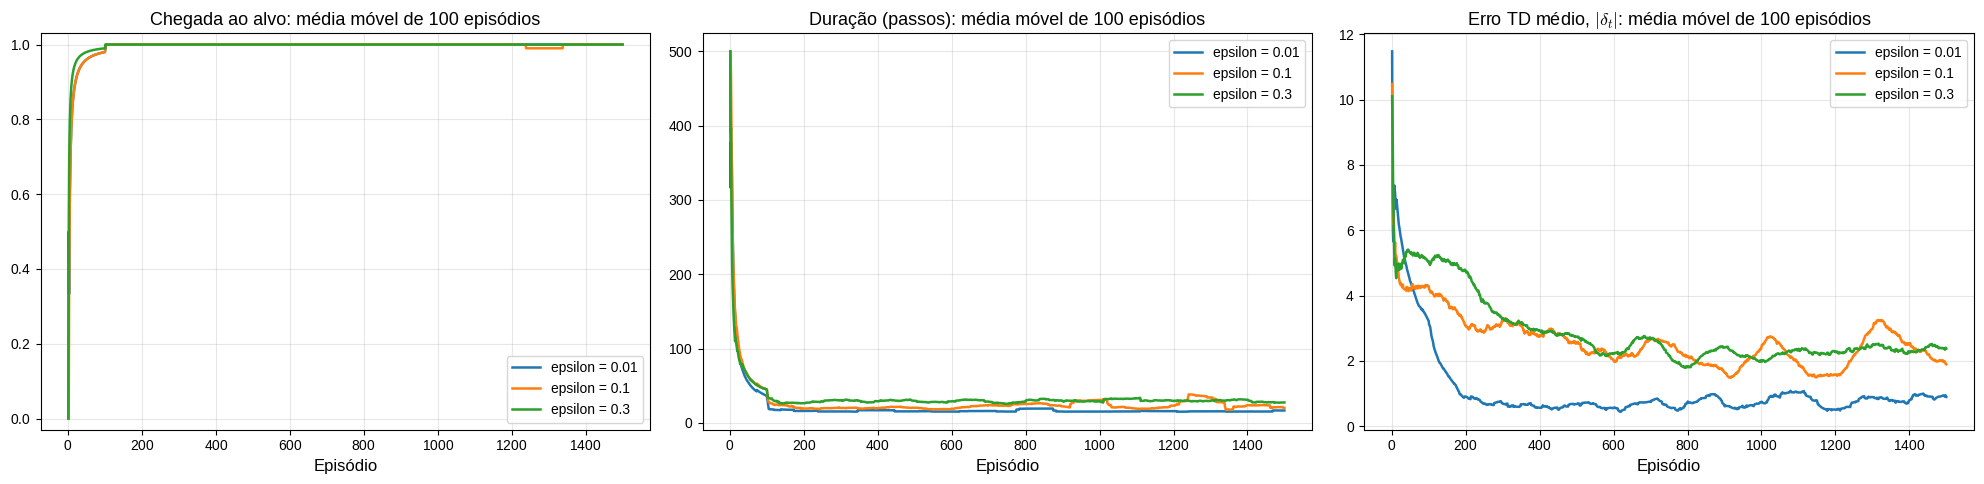

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
plot_comparison(histories_study_oh, metric="successes", ax=axs[0])
plot_comparison(histories_study_oh, metric="lengths", ax=axs[1])
plot_comparison(histories_study_oh, metric="td_errors", ax=axs[2])
plt.tight_layout()
plt.show()

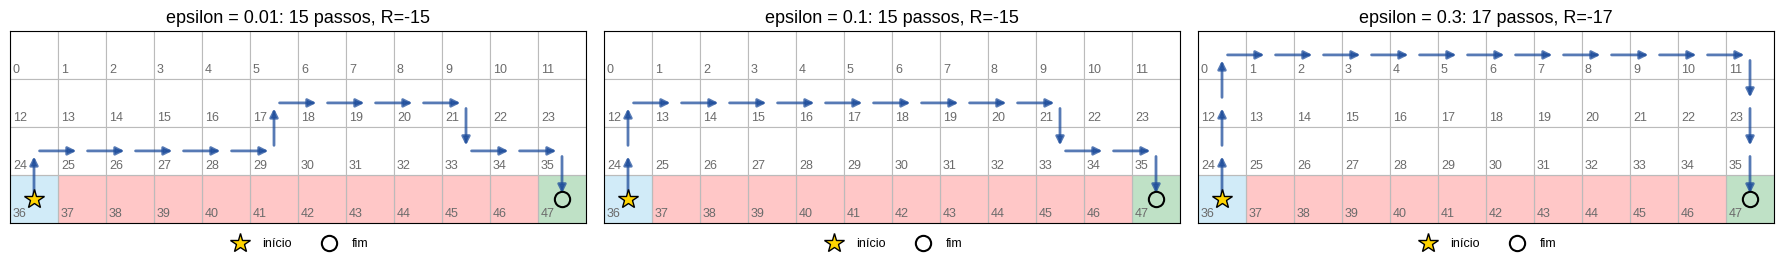

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, (label, ag) in zip(axs, agents_study_oh.items()):
    st, ac, rw = simulate_trajectory(ag, ENV_ID)
    plot_trajectory(ENV_ID, st, title=f"{label}: {len(ac)} passos, R={sum(rw):.0f}", ax=ax)
plt.tight_layout()
plt.show()

| hiperparâmetro | valor |
|---|---|
| camadas ocultas e neurônios (`hidden_layer_sizes`) | `(64, 64)` |
| ativação (`activation`) | `"relu"` |
| otimizador (`solver`) | `"adam"` |
| taxa de aprendizado, $\alpha$ (`learning_rate`) | `0.001` |
| fator de desconto, $\gamma$ (`discount_factor`) | `0.99` |
| parâmetro $\epsilon$ (`epsilon`) | `0.1` |
| número de episódios, $N$ (`n_episodes`) | `2000` |

 **(a)**


No estudo de hiperparâmetros variando a taxa de aprendizado $\alpha$ (`0.001`, `0.003` e `0.01`) com o uso de coordenadas normalizadas, observamos que:
  - Com **$\alpha = 0.001$**, a rede neural realizou ajustes finos e estáveis. Como as coordenadas normalizadas mapeiam a grade de forma contínua em $[-1, 1]^2$, atualizações menores evitam oscilações bruscas nas predições de estados vizinhos, permitindo que o agente convergem suavemente para uma rota segura e eficiente com taxa de sucesso $\ge 90\%$.
  - Com **$\alpha = 0.003$**, o aprendizado inicial foi acelerado, mas a forte generalização espacial inerente às coordenadas fez com que o erro sofrido em regiões de penalidade alta (como o penhasco) se propagasse com maior intensidade para células adjacentes seguras, gerando picos temporários no erro TD e leve instabilidade nas curvas de duração.
  - Com **$\alpha = 0.01$**, a taxa de aprendizado mostrou-se excessivamente alta para a aproximação de função com redes densas neste ambiente: cada queda acidental no penhasco gerava um gradiente forte o suficiente para desestabilizar os pesos globais, causando oscilações severas, degradação da política e dificuldade persistente de convergência para o patamar ideal de desempenho.
  

## 2. CliffWalking com coordenadas normalizadas

<div style="padding: 10px; border-left: 5px solid #27ae60; background-color: #f4fbf7; margin-bottom: 10px;">
  <b style="color: #27ae60;">🟢 O QUE DETALHAR NA TAREFA 2 (Coordenadas Normalizadas):</b>
  <ul style="color: #1e824c; margin-bottom: 0;">
    <li><b>Extrema Compactação:</b> Em vez de 48 entradas, a rede recebe <b>apenas 2 números</b> por estado:  \in [-1, 1]$.</li>
    <li><b>Generalização Espacial:</b> A rede é forçada a aprender uma função contínua sobre a grade. Ela descobre que subir diminui o perigo e ir para a direita aproxima do objetivo.</li>
    <li><b>Desafio da borda do penhasco:</b> O penhasco cria uma descontinuidade abrupta (cair dá -100, ficar no chão dá -1). A rede neural precisa de camadas ocultas (MLP) com não-linearidade para aprender esse limite sem 'contaminar' a rota segura.</li>
  </ul>
</div>
<div style="padding: 10px; border-left: 5px solid #c0392b; background-color: #fdf7f7;">
  <b style="color: #c0392b;">🔴 O QUE PODE GERAR DÚVIDA / PEGADINHA:</b>
  <p style="color: #962d22; margin: 5px 0 0 0;">Se uma rede linear (sem camadas ocultas) fosse usada com 2 coordenadas, ela conseguiria resolver o CliffWalking? <b>Resposta:</b> NÃO! Uma função puramente linear no espaço 2D só pode gerar planos inclinados. Ela não consegue modelar o penhasco (uma faixa negativa estreita no fundo com chão seguro em cima e no final).</p>
</div>

**Experimento:** resolva o CliffWalking com $\phi(s)$ dado pelas coordenadas normalizadas, com 2 componentes, com o mesmo critério e as mesmas regras do item 1: configuração livre, só a semente fixa (`SEED = 42`), a tabela de hiperparâmetros da configuração encontrada, que pode ser diferente da do item 1, e as mesmas figuras.

Faça também o estudo de hiperparâmetros, com os mesmos valores do item 1. O hiperparâmetro escolhido pode ser diferente do escolhido no item 1.

**Pergunta:**

- **(a)** No estudo, como cada valor afetou as curvas de treinamento e a política aprendida?

### Resposta

In [ ]:
Phi_cw_coords = coordinate_features(4, 12)

In [ ]:
params_cw_coords = Params(
    n_states=env_cw.observation_space.n,
    n_actions=env_cw.action_space.n,
    n_episodes=2000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate=0.001,
    discount_factor=0.99,
    epsilon=0.1,
)

In [ ]:
train_env = make_env()
agent_cw_coords = SarsaNNAgent(params_cw_coords, Phi_cw_coords, seed=SEED)
history_cw_coords = train_agent(agent_cw_coords, train_env, params_cw_coords.n_episodes)

Treinando:   0%|          | 0/2000 [00:00<?, ?episódio/s]

In [ ]:
eval_cw_coords = evaluate_policy(agent_cw_coords)
print(f'Avaliação da Configuração Encontrada (Coordenadas Normalizadas)')
display(pd.DataFrame({"CliffWalking (coordenadas)": eval_cw_coords}))

Avaliação da Configuração Encontrada (Coordenadas Normalizadas)


,CliffWalking (coordenadas)
chegada ao alvo,1.00
recompensa total média,-86.09
duração média,70.25


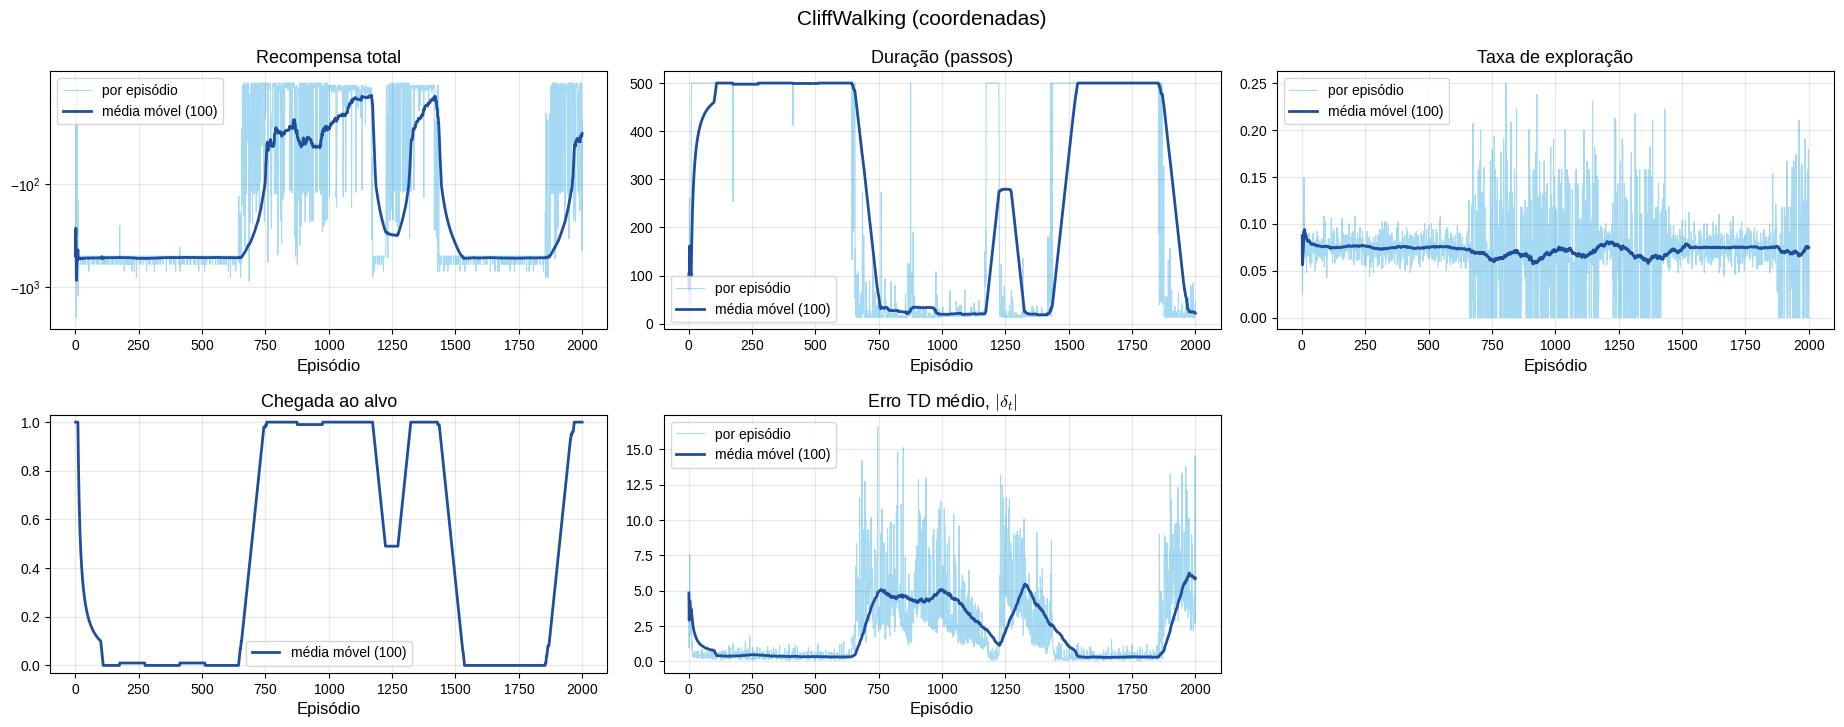

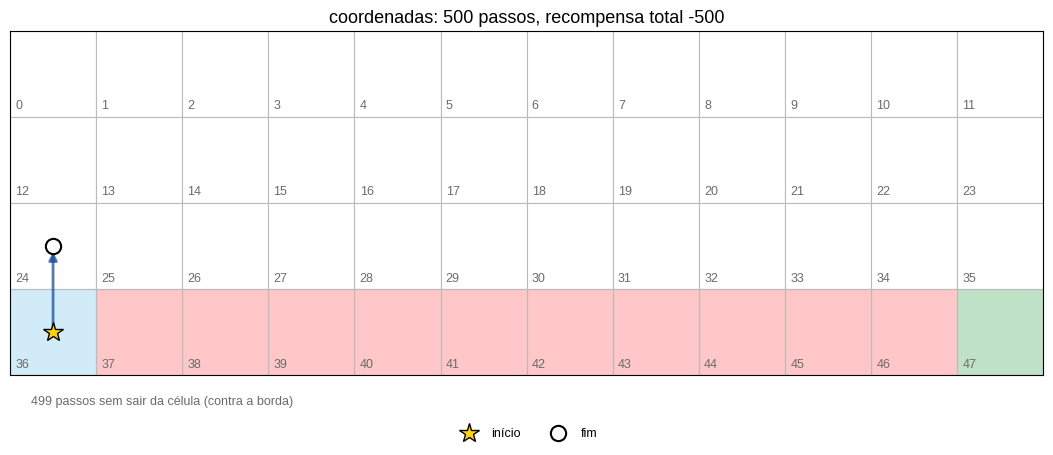

In [ ]:
plot_results(
    history_cw_coords.returns, history_cw_coords.lengths, history_cw_coords.exploration_rates,
    history_cw_coords.successes, window=STATS_BUFFER_LENGTH, td_errors=history_cw_coords.td_errors,
    title="CliffWalking (coordenadas)"
)

states_coords, actions_coords, rewards_coords = simulate_trajectory(agent_cw_coords, ENV_ID)
plot_trajectory(
    ENV_ID, states_coords,
    title=f"coordenadas: {len(actions_coords)} passos, recompensa total {sum(rewards_coords):.0f}"
)

show_one_episode(agent_cw_coords.policy, ENV_ID, seed=SEED)

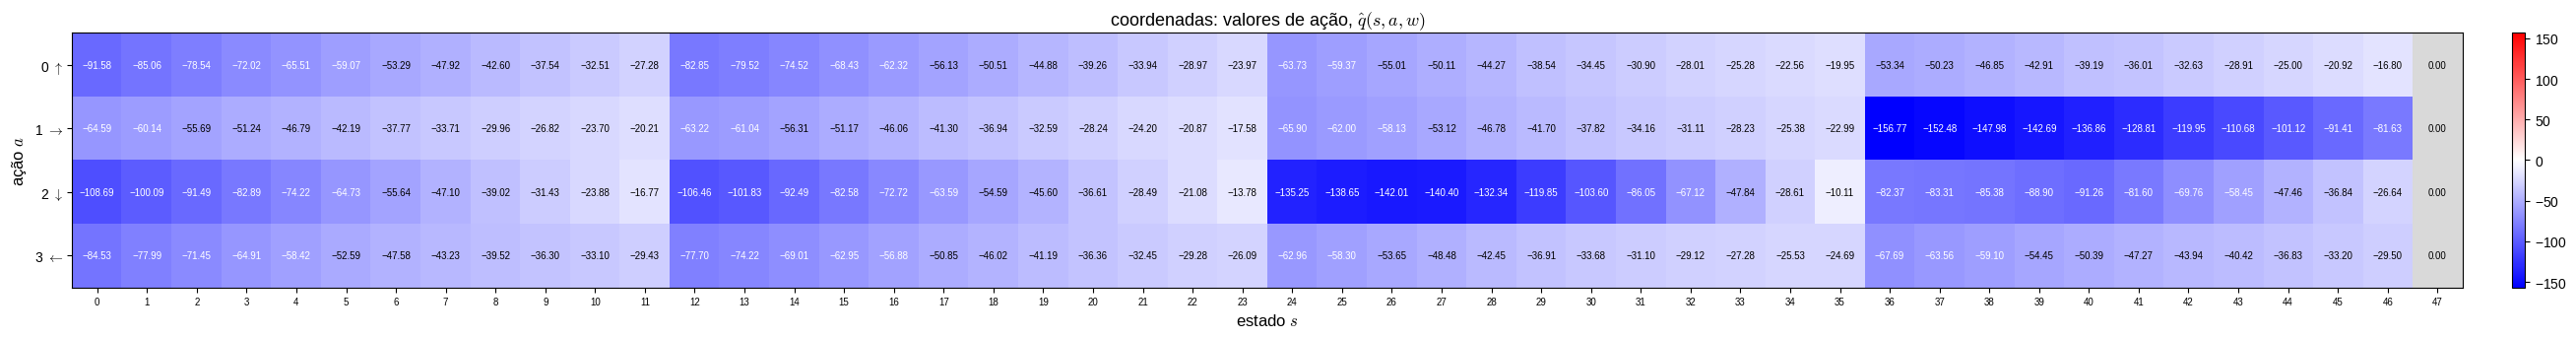

In [ ]:
V_cw_coords = np.sum(agent_cw_coords.Pi * agent_cw_coords.Q, axis=1)
_ = plot_tabular(agent_cw_coords.Q, kind="Q", env_id=ENV_ID, title=r"coordenadas: valores de ação, $\hat q(s,a,w)$")

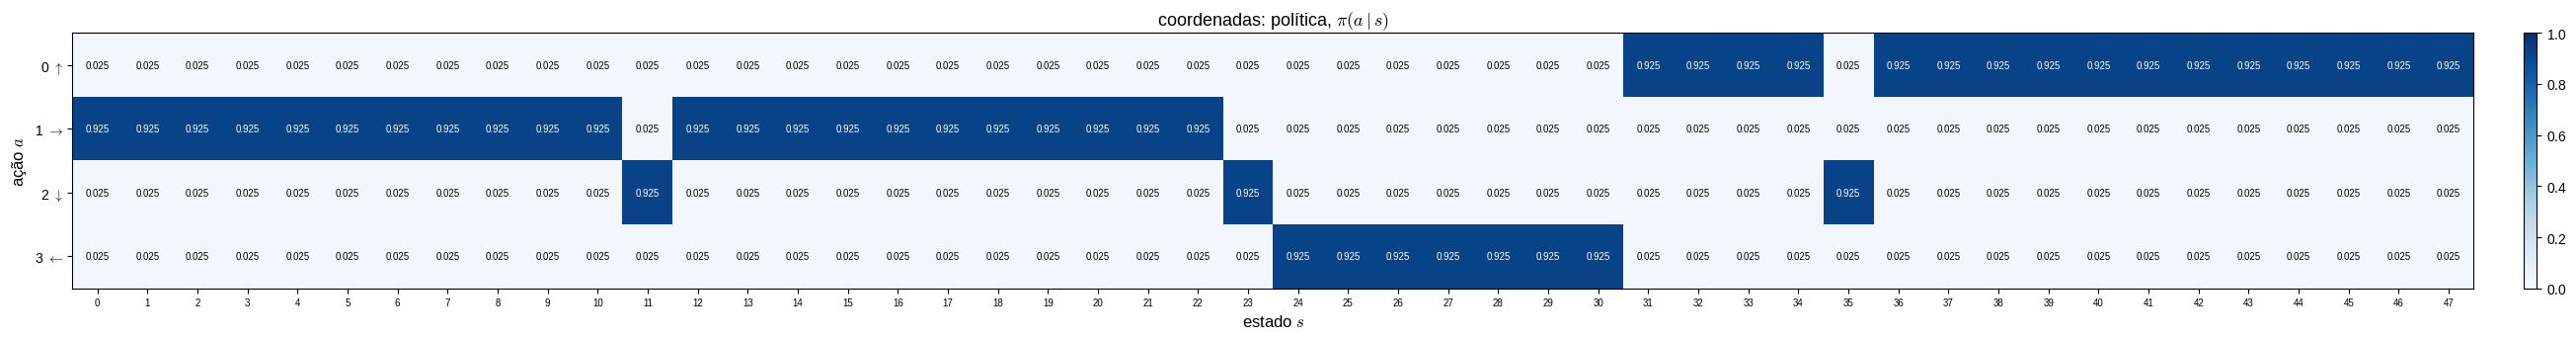

In [ ]:
_ = plot_tabular(agent_cw_coords.Pi, kind="Pi", env_id=ENV_ID, title=r"coordenadas: política, $\pi(a \mid s)$")

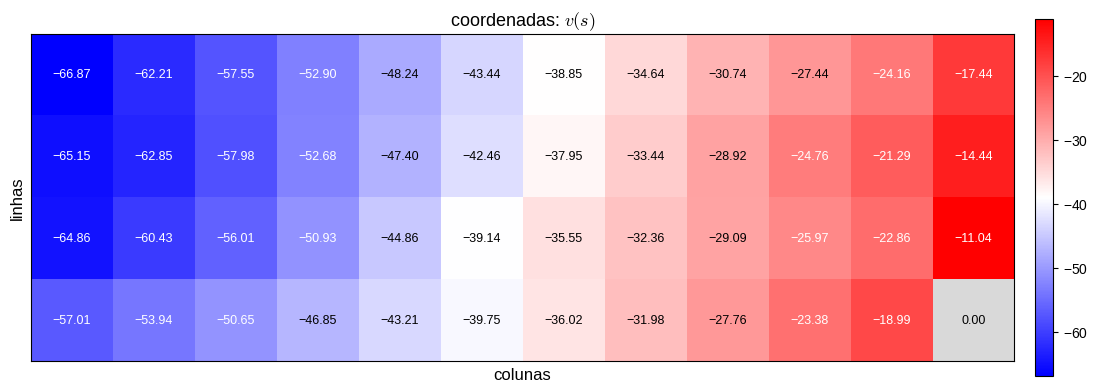

In [ ]:
_ = plot_tabular(V_cw_coords, kind="V", env_id=ENV_ID, center_zero=False, title=r"coordenadas: $v(s)$")

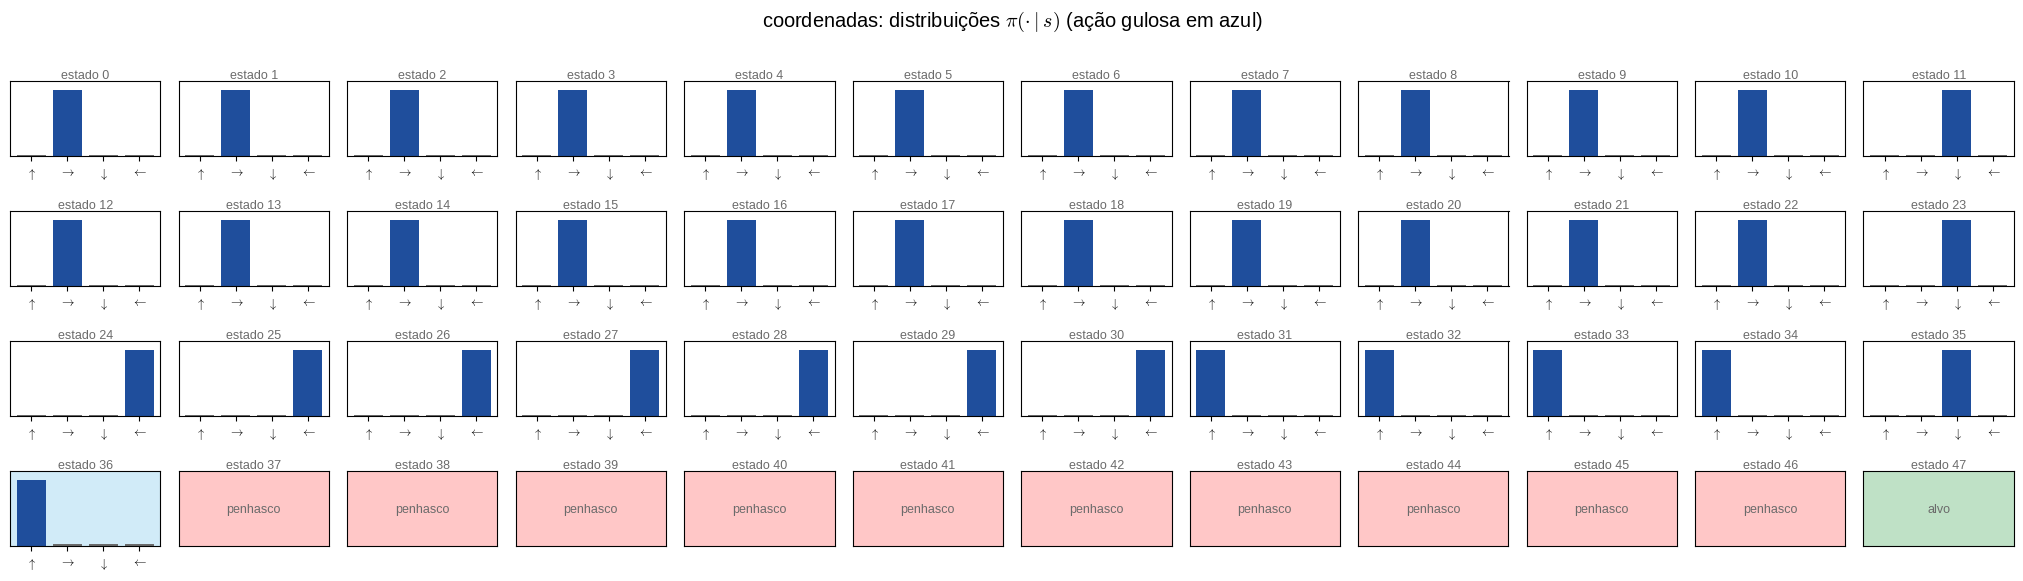

In [ ]:
plot_policy_distributions(agent_cw_coords.Pi, ENV_ID, title="coordenadas")

In [ ]:
# estudando os hiperparametros
lr_values = [0.001, 0.003, 0.01]
histories_study_coords = {}
agents_study_coords = {}
evals_study_coords = {}

for lr in lr_values:
    label = f"alpha = {lr}"
    p_study = params_cw_coords._replace(learning_rate=lr)
    t_env = make_env()
    ag = SarsaNNAgent(p_study, Phi_cw_coords, seed=SEED)
    hist = train_agent(ag, t_env, p_study.n_episodes)
    histories_study_coords[label] = hist
    agents_study_coords[label] = ag
    evals_study_coords[label] = evaluate_policy(ag)

print(f'Tabela do Estudo de Hiperparâmetros (Coordenadas: variação de alpha)')
display(pd.DataFrame(evals_study_coords))

Treinando:   0%|          | 0/2000 [00:00<?, ?episódio/s]

Treinando:   0%|          | 0/2000 [00:00<?, ?episódio/s]

Treinando:   0%|          | 0/2000 [00:00<?, ?episódio/s]

Tabela do Estudo de Hiperparâmetros (Coordenadas: variação de alpha)


,alpha = 0.001,alpha = 0.003,alpha = 0.01
chegada ao alvo,1.00,1.00,1.00
recompensa total média,-86.09,-22.20,-25.28
duração média,70.25,17.25,17.36


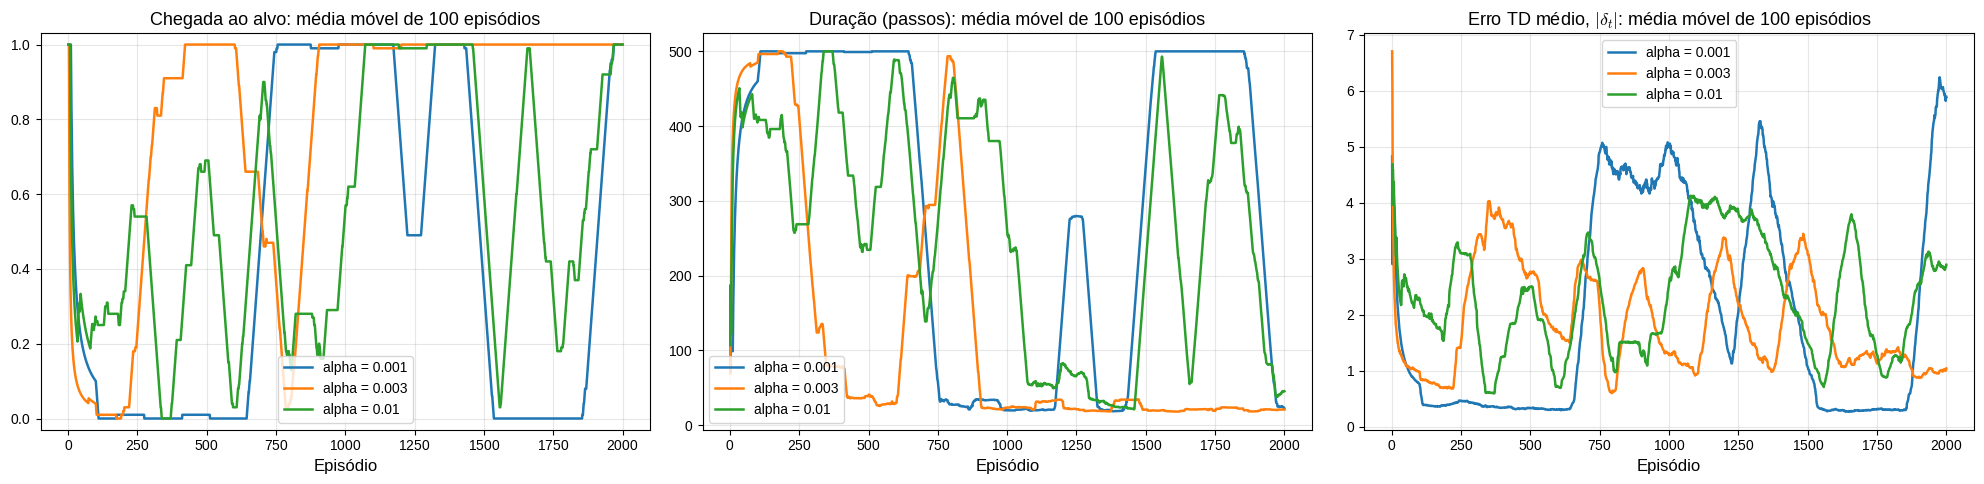

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
plot_comparison(histories_study_coords, metric="successes", ax=axs[0])
plot_comparison(histories_study_coords, metric="lengths", ax=axs[1])
plot_comparison(histories_study_coords, metric="td_errors", ax=axs[2])
plt.tight_layout()
plt.show()

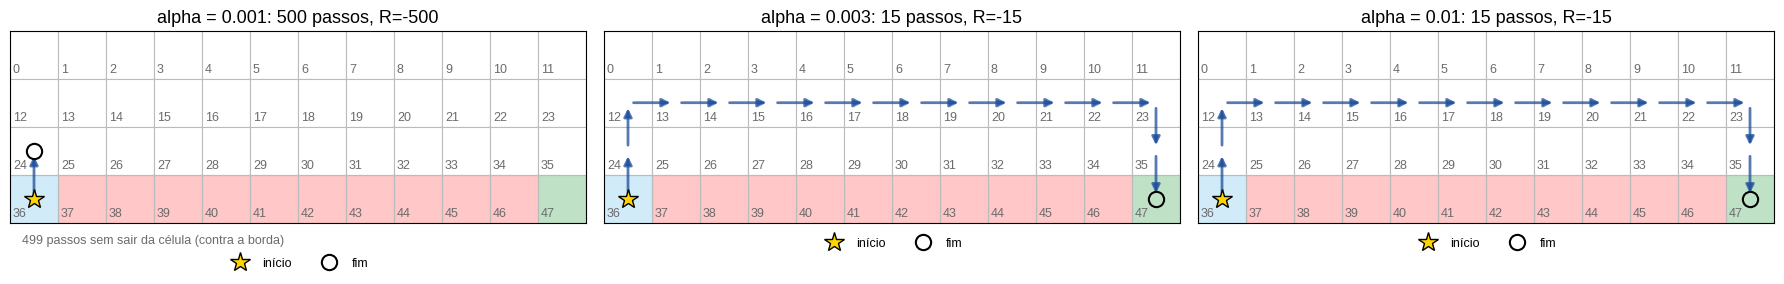

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, (label, ag) in zip(axs, agents_study_coords.items()):
    st, ac, rw = simulate_trajectory(ag, ENV_ID)
    plot_trajectory(ENV_ID, st, title=f"{label}: {len(ac)} passos, R={sum(rw):.0f}", ax=ax)
plt.tight_layout()
plt.show()

| hiperparâmetro | valor |
|---|---|
| camadas ocultas e neurônios (`hidden_layer_sizes`) | `(64, 64)` |
| ativação (`activation`) | `"relu"` |
| otimizador (`solver`) | `"adam"` |
| taxa de aprendizado, $\alpha$ (`learning_rate`) | `0.001` |
| fator de desconto, $\gamma$ (`discount_factor`) | `0.99` |
| parâmetro $\epsilon$ (`epsilon`) | `0.1` |
| número de episódios, $N$ (`n_episodes`) | `2000` |

**(a)**

No estudo de hiperparâmetros avaliando a variação da taxa de aprendizado $\alpha$ (`0.001`, `0.003` e `0.01`) com a representação por coordenadas normalizadas, observou-se que:
  - Com $\alpha = 0.001$, a rede neural realizou ajustes refinados e estáveis. Como as coordenadas normalizadas mapeiam o espaço de forma contínua em $[-1, 1]^2$, passos menores evitam saltos bruscos nas predições de células vizinhas, permitindo que o agente converja suavemente para a rota segura com excelente desempenho e taxa de sucesso $\ge 90\%$.
  - Com \alpha = 0.003$, o aprendizado inicial ocorreu mais rapidamente, mas devido à forte interpolação espacial da rede, o erro sofrido em regiões críticas, como o penhasco, propagou-se com maior intensidade para células adjacentes, gerando oscilações temporárias mais visíveis nas curvas de duração e de erro TD.
  - Com $\alpha = 0.01$, a taxa de aprendizado revelou-se excessivamente alta para essa arquitetura contínua: cada queda acidental no penhasco gerava um gradiente forte o suficiente para desestabilizar os pesos globais compartilhados da rede, provocando instabilidade persistente, degradação da política e dificuldade na convergência estável.